> **Вариант 1 выключен** (`RUN_V1 = False` в `common/settings.py`): ноутбук остановится на проверке. Чтобы вернуть расчёт, поставить `True`.

# 01. Журнал состояний и все майнеры: окно с 2013-01-01

> **Пересчёт.** Основа — `petri_states.ipynb` из папки `петри`; код расчёта тот же, пути и флаги — из `common/settings.py`. Здесь считается одна часть (окно с 2013-01-01), флаги 15 / 365. **Самый тяжёлый по памяти ноутбук** (см. README); метрики сохраняются по одной модели, после сбоя ячейку можно запустить снова. Текст с числами и выводами написан по **прежнему** расчёту: после пересчёта сверить (`common/compare_with_old.py`).

# Сети Петри на журнале состояний (04.11.2026)

Запись базы — не отдельное событие, а часть **состояния** человека. Человек всегда в одном из состояний: на свободе (`free`), в заключении (`jail` / `prison`), под арестом или обвинением по делу (`arrest`, `charge`, `arrest+charge`) или в составном состоянии «дело + заключение» (`arrest+charge+jail` и т. п.).

**Эксперименты** (без уточнённой разметки активностей):

| Эксперимент | Окно | Папка |
|---|---|---|
| `all` | вся история базы | `out_states\all\` |
| `2013` | с 2013-01-01 (есть `jailhistory`) | `out_states\2013\` |

**Метрики пока без разбиения train/test и без alignments**: сеть строится на всём журнале, fitness (token replay) и precision (ETC) считаются на нём же. Следующий шаг — лучшие майнеры с разбиением людей 80/20 и alignments (в задачах).

Логика — в `petri_states.py` (журнал состояний) и `petri_pipeline.py` (таблица 1, эпизоды заключения, майнеры).

## Правила журнала состояний

| № | Ситуация | Правило |
|---|---|---|
| 1 | Несколько записей **одного дела за один день** | одно состояние: все аресты → `arrest`, все обвинения → `charge`, оба → `arrest+charge` |
| 2 | Несколько дел в один день | по состоянию на дело, порядок по номеру дела, между ними `free` нет |
| 3 | Вход в заключение в день D, **одно** дело в этот день, заключение короче `LONG_CUSTODY_DAYS` | составное состояние: `arrest+jail`, `charge+jail`, `arrest+charge+jail` (то же с `prison`); время — вход в заключение |
| 4 | Вход в заключение, **несколько** дел в этот день | состояния дел (по номеру), затем отдельно `jail` / `prison` |
| 5 | Заключение **длинное** (≥ `LONG_CUSTODY_DAYS`, флаг, 365 дней) и аресты/обвинения в день входа | аресты/обвинения — отдельными состояниями **перед** заключением |
| 6 | Аресты/обвинения **внутри срока**, заключение **короткое** (< `SHORT_CUSTODY_DAYS`, флаг, 15 дней) | склеиваются с состоянием заключения (его имя дополняется: `jail` → `charge+jail`) |
| 7 | Аресты/обвинения внутри срока, заключение не короткое | `jail → arrest/charge → jail`: возврат в заключение в D+1 00:00, если на следующий день внутри срока событий нет |
| 8 | Перевод jail → prison внутри эпизода | отдельное состояние `prison` |
| 9 | Выход из заключения | `free` во время `out_custody`; **не ставится**, если следующее событие в тот же или на следующий день (переход сразу в новое состояние) |
| 10 | Арест/обвинение без заключения | если на следующий день событий нет — `free` в D+1 00:00, иначе сразу следующее состояние |
| 11 | Начало трассы | без окна — первое состояние; в окне — состояние на 2013-01-01: `free` или `jail`/`prison`, если человек тогда сидел |
| 12 | Конец трассы | `end` (конец наблюдения 2016-04-19 07:19:36) — только из `free`, `jail` или `prison` |

Время состояния дела без заключения — дата (00:00); одинаковое время разводится на 1 мс в порядке состояний.

## Шаг 0. Настройки

| Параметр | Значение | Смысл |
|---|---|---|
| `EXPERIMENTS` | `all`: без окна, `2013`: с 2013-01-01 | эксперименты |
| `SHORT_CUSTODY_DAYS` | 15 | флаг: заключение короче — события внутри срока склеиваются с ним (правило 6). Медиана длительности — в шаге 1.1 |
| `LONG_CUSTODY_DAYS` | 365 | флаг: заключение длиннее — аресты/обвинения дня входа ставятся перед ним (правило 5) |
| `IM_NOISE`, `HM_DEP`, `DFG_MIN_PROB` | (0, 0.2), (0.9, 0.95, 0.99), (0, 0.05) | пороги майнеров |
| `RUN_EVAL` | `False` | `True` — пересчитать метрики (окно 2013 — около 15 минут, вся история — около 1,5 часа; нужно ~3 ГБ памяти); `False` — взять `out_states\<эксперимент>\model_quality.csv` |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "common"))
import settings as cfg

PART = "2013"                         # "2013" — с окном, "all" — без окна

CONFIG = "long365_v1"
OUT = cfg.out_dir(PART, CONFIG)
DB_CANDIDATES = cfg.DB_CANDIDATES
CATEGORIES_DIRS = cfg.CATEGORIES_DIRS

EXPERIMENTS = {PART: cfg.PARTS[PART]["log_start"]}
SHORT_CUSTODY_DAYS = cfg.CONFIGS[CONFIG]["short"]   # флаг: короткое заключение (правило 6)
LONG_CUSTODY_DAYS = cfg.CONFIGS[CONFIG]["long"]     # флаг: длинное заключение (правило 5)

IM_NOISE = (0.0, 0.2)
HM_DEP = (0.9, 0.95, 0.99)
DFG_MIN_PROB = (0.0, 0.05)
RUN_EVAL = True                  # True — пересчитать метрики


In [2]:
assert cfg.RUN_V1, "Вариант 1 выключен: RUN_V1 = False в common/settings.py. Этот ноутбук запускать не нужно."

In [3]:
import sys, time, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Image

warnings.filterwarnings("ignore")
import petri_pipeline as pp
import petri_states as ps
import pm4py

OUT.mkdir(parents=True, exist_ok=True)
DB = pp.find_db(DB_CANDIDATES)
categorize = pp.import_categorizer(CATEGORIES_DIRS)
HAS_DOT = pp.setup_graphviz()
pd.set_option("display.max_columns", 30, "display.width", 220)
print("база:", DB)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__, "| Graphviz:", "есть" if HAS_DOT else "НЕТ")



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




база: D:\diploma\jupyter lab\петри_пересчет\data\compas.db
pm4py 2.7.23.9 | pandas 2.3.3 | Graphviz: есть


## Шаг 1. Таблица истории (этап 1, как в `petri_nets.ipynb`)

Полные дубли удаляются, пребывания со входом позже выхода — тоже.

In [4]:
tables, dup_report = pp.drop_full_duplicates(pp.load_tables(DB))
tables, bad_stays_report, _ = pp.drop_invalid_stays(tables)
hist = pp.build_history_table(tables, categorize)
display(dup_report)
display(bad_stays_report)
print(f"таблица 1: {len(hist):,} строк, {hist.person_id.nunique():,} человек")

,table,rows,full_duplicates,kept
0,jailhistory,22111,0,22111
1,prisonhistory,4945,0,4945
2,casearrest,128183,2242,125941
3,charge,148086,13,148073


,table,rows,in_after_out,kept
0,jailhistory,22111,821,21290
1,prisonhistory,4945,0,4945


таблица 1: 300,249 строк, 11,473 человек


### 1.1. Длительность заключений (для флагов `SHORT_CUSTODY_DAYS` / `LONG_CUSTODY_DAYS`)

Эпизод заключения — склеенные пребывания jail/prison (пересечение или перевод jail → prison в течение суток). Кто сидит на конец наблюдения — длительность до конца наблюдения.

In [5]:
obs_end = pp.observation_end(hist)
_, episodes = pp.custody_episodes(hist, obs_end)
dur = (episodes["ep_end"].fillna(obs_end) - episodes["ep_start"]).dt.total_seconds() / 86400
display(dur.describe(percentiles=[.1, .25, .5, .75, .9, .95]).round(1).to_frame("дней").T)
print(f"короче {SHORT_CUSTODY_DAYS} дн.: {(dur < SHORT_CUSTODY_DAYS).mean():.1%};  "
      f"{LONG_CUSTODY_DAYS} дн. и дольше: {(dur >= LONG_CUSTODY_DAYS).mean():.1%}")
pd.cut(dur, [-1, 1, 7, 15, 30, 90, 180, 365, 1e6],
       labels=["≤1", "1–7", "7–15", "15–30", "30–90", "90–180", "180–365", ">365"]).value_counts(sort=False).to_frame("эпизодов").T

,count,mean,std,min,10%,25%,50%,75%,90%,95%,max
дней,25231.0,131.0,351.8,0.0,0.7,1.1,7.3,82.0,390.0,707.5,7474.0


короче 15 дн.: 56.1%;  365 дн. и дольше: 10.6%


,≤1,1–7,7–15,15–30,30–90,90–180,180–365,>365
эпизодов,5395,7047,1709,1621,3390,1618,1789,2662


## Шаг 2. Журналы состояний

In [6]:
LOGS, REPORTS = {}, {}
for key, start in EXPERIMENTS.items():
    t0 = time.time()
    log, eps, rep = ps.build_state_log(hist, obs_end=obs_end, log_start=start,
                                       short_days=SHORT_CUSTODY_DAYS, long_days=LONG_CUSTODY_DAYS)
    LOGS[key], REPORTS[key] = log, rep
    d = OUT
    log.to_csv(d / "state_log.csv", index=False)
    print(f"{key}: {time.time() - t0:.0f} с, сохранено {d / 'state_log.csv'}")
    for line in ps.check_state_log(log):
        print("   OK:", line)
pd.DataFrame(REPORTS).rename_axis("показатель")

2013: 100 с, сохранено D:\diploma\jupyter lab\петри_пересчет\с_окном_2013\out\long365_v1\state_log.csv
   OK: время внутри каждой трассы строго возрастает
   OK: перед end: {'free': 10590, 'prison': 647, 'jail': 40}; не free/заключение: 0
   OK: free → free подряд: 0


,2013
показатель,
obs_end,2016-04-19 07:19:36
composite,13228
absorbed_units,181
inside_units,1609
returns,1167
free_after_case,16806
free_after_custody,20738
no_free_next_day,202
started_inside,143


Показатели: `composite` — составных состояний «дело + заключение»; `absorbed_units` — дел внутри коротких сроков, склеенных с заключением; `inside_units` / `returns` — состояний внутри срока и возвратов в заключение; `free_after_case` / `free_after_custody` — выходов в `free` после ареста/обвинения и после заключения; `no_free_next_day` — выходов из заключения без `free` (следующее событие в тот же или на следующий день); `started_inside` — трасс окна, начатых в заключении.

In [7]:
# состояния: сколько и доля
pd.concat({k: l["activity"].value_counts() for k, l in LOGS.items()}, axis=1).fillna(0).astype(int)

,2013
activity,
free,48678
charge,15444
end,11277
arrest,9585
jail,9146
arrest+charge+jail,8495
arrest+charge,8055
arrest+jail,4760
prison,1340


In [8]:
# длина трасс
pd.concat({k: l.groupby("person_id").size().describe(percentiles=[.5, .9]).round(1) for k, l in LOGS.items()}, axis=1).T

,count,mean,std,min,50%,90%,max
2013,11277.0,10.4,7.2,3.0,8.0,20.0,99.0


### 2.1. Примеры трасс (окно 2013)

- 8399: вышел из jail 13.05.2014 в 02:09 и в тот же день сел по новому делу — переход сразу в `arrest+charge+jail`, без `free` (правило 9);
- 7433: 6 записей одного дела за день → одно `arrest+charge`, на следующий день событий нет → `free` 28.05 00:00;
- 6266: два дела в один день → по номеру дела, затем `free`;
- 4781: обвинение 09.10 → `free` 10.10 → `arrest+jail` 15.10;
- 10897: два дела и jail в один день → дела, затем `jail`.

In [9]:
cols = ["person_id", "activity", "ts", "ts_raw", "kind", "cases", "n_records"]
ex = [(8399, "2014-04-20", "2014-06-01"), (7433, "2013-01-01", "2014-09-01"), (6266, "2013-01-01", "2016-05-01"),
      (4781, "2013-10-01", "2014-07-01"), (10897, "2015-08-01", "2015-12-31")]
l13 = next(iter(LOGS.values()))
pd.concat([l13[(l13.person_id == p) & l13.ts.between(a, b)][cols] for p, a, b in ex])

,person_id,activity,ts,ts_raw,kind,cases,n_records
83612,8399,arrest,2014-04-24 00:00:00.000,2014-04-24 00:00:00,case,11014148CF10A,1
83613,8399,arrest,2014-04-24 00:00:00.001,2014-04-24 00:00:00,case,11015175CF10A,1
83614,8399,arrest,2014-04-24 00:00:00.002,2014-04-24 00:00:00,case,14001618CF10A,1
83615,8399,jail,2014-04-24 12:47:04.000,2014-04-24 12:47:04,custody,,0
83616,8399,arrest+charge+jail,2014-05-13 07:37:33.000,2014-05-13 07:37:33,custody,,0
83617,8399,free,2014-05-14 08:23:25.000,2014-05-14 08:23:25,free_release,,0
83618,8399,charge,2014-05-21 00:00:00.000,2014-05-21 00:00:00,case,14037872TI20A,1
83619,8399,free,2014-05-22 00:00:00.000,2014-05-22 00:00:00,free_case,,0
73895,7433,free,2013-01-01 00:00:00.000,2013-01-01 00:00:00,start,,0
73896,7433,arrest+charge,2013-05-27 00:00:00.000,2013-05-27 00:00:00,case,13007547CF10A,6


### 2.2. Матрица directly-follows (вероятность перехода и медиана времени, дни)

In [10]:
for key, log in LOGS.items():
    cnt, prob, med = pp.directly_follows(log)
    print(f"=== {key}: вероятность перехода")
    display(prob.round(2))
    print(f"=== {key}: медиана времени, дни")
    display(med.round(1))

=== 2013: вероятность перехода


next_activity,free,arrest,charge,jail,prison,end,arrest+charge,arrest+charge+jail,arrest+jail,charge+jail
activity,,,,,,,,,,
free,0.00,0.10,0.29,0.03,0.01,0.22,0.09,0.17,0.09,0.0
arrest,0.18,0.30,0.01,0.30,0.00,0.00,0.21,0.00,0.00,0.0
charge,0.89,0.01,0.04,0.03,0.00,0.00,0.01,0.01,0.01,0.0
jail,0.82,0.07,0.01,0.00,0.08,0.00,0.01,0.00,0.00,0.0
prison,0.44,0.04,0.01,0.02,0.00,0.48,0.00,0.00,0.00,0.0
arrest+charge,0.16,0.05,0.06,0.52,0.00,0.00,0.20,0.00,0.01,0.0
arrest+charge+jail,0.96,0.03,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.0
arrest+jail,0.94,0.03,0.00,0.00,0.02,0.00,0.00,0.00,0.00,0.0
charge+jail,0.88,0.12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0


=== 2013: медиана времени, дни


next_activity,free,arrest,charge,jail,prison,end,arrest+charge,arrest+charge+jail,arrest+jail,charge+jail
activity,,,,,,,,,,
free,NaN,88.0,104.6,136.2,198.0,523.9,119.0,140.5,92.2,87.2
arrest,1.0,0.0,0.0,0.5,1.0,NaN,0.0,1.2,1.1,NaN
charge,1.0,1.0,0.0,0.3,1.0,NaN,0.0,1.2,1.2,NaN
jail,6.3,11.0,26.8,23.3,131.7,293.0,15.0,2.8,3.4,NaN
prison,221.0,99.0,145.0,169.4,248.0,280.3,182.0,NaN,374.6,NaN
arrest+charge,1.0,0.0,0.0,0.4,1.0,NaN,0.0,1.3,1.1,1.1
arrest+charge+jail,1.2,2.7,1.8,0.6,110.7,NaN,3.1,2.6,8.1,NaN
arrest+jail,7.8,11.6,17.6,201.5,34.8,NaN,4.8,3.0,89.3,NaN
charge+jail,1.6,0.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# самые частые варианты (повторы подряд свёрнуты: X+ = несколько X подряд)
for key, log in LOGS.items():
    var = log.groupby("person_id")["activity"].agg(lambda s: " → ".join(pp.collapse_repeats(s)))
    vc = var.value_counts()
    print(f"=== {key}: {len(vc):,} вариантов на {len(var):,} трасс")
    display(pd.DataFrame({"людей": vc.head(12), "доля": (vc.head(12) / len(var)).round(4)}))

=== 2013: 4,722 вариантов на 11,277 трасс


,людей,доля
activity,,
free → arrest+charge+jail → free → end,1644,0.1458
free → arrest+charge+jail → free → charge → free → end,366,0.0325
free → jail → free → end,308,0.0273
free → charge → free → arrest+charge+jail → free → end,279,0.0247
free → arrest+charge+ → jail → free → end,230,0.0204
free → arrest+charge → jail → free → end,228,0.0202
free → arrest+charge+jail → free → arrest+jail → free → end,184,0.0163
free → arrest+jail → free → end,130,0.0115
free → charge → free → arrest+jail → free → end,120,0.0106


## Шаг 3. Сети Петри: все майнеры, весь журнал

| Модель | Функция PM4Py |
|---|---|
| Inductive Miner (шум 0 / 0.2) | `discover_petri_net_inductive` |
| Heuristics Miner (0.9 / 0.95 / 0.99) | `discover_petri_net_heuristics` |
| Split Miner | `discover_bpmn_split_miner` → `convert_to_petri_net` (только свежие версии PM4Py, иначе пропускается) |
| POWL | `discover_powl` → `convert_to_petri_net` |
| Сеть из DFG (p0 / p0.05) | `discover_dfg` → `convert_to_petri_net` |
| Alpha / Alpha+ | `discover_petri_net_alpha` / `discover_petri_net_alpha_plus` |
| цветочная | разрешает любую последовательность — базовая линия precision |

ILP Miner и Genetic Miner не используются (ILP на наших трассах не помещается в память, Genetic считается часами).

Метрики: `fitness_tbr` (`fitness_token_based_replay`), `pct_fit_traces_tbr`, `precision_etc` (`precision_token_based_replay`), `precision_norm = (P − P_flower)/(1 − P_flower)`, `f1`. **Сеть строится и проверяется на одном и том же журнале** (без разбиения train/test) — это оценка того, насколько хорошо модель описывает данные, а не прогноза.

In [12]:
LPM, MODELS, infos = {}, {}, []
for key, log in LOGS.items():
    LPM[key] = pp.to_pm4py(log)
    MODELS[key], info = ps.discover_all(LPM[key], im_noise=IM_NOISE, hm_dep=HM_DEP, dfg_min_prob=DFG_MIN_PROB)
    infos.append(info.assign(experiment=key))
pd.concat(infos, ignore_index=True).set_index(["experiment", "model"]).round(2)

discover_sec status  places  transitions  silent
experiment model                                                        
2013       IM_noise0.0          0.40     ok      37           48      38
           IM_noise0.2          0.41     ok      35           44      34
           HM_dep0.9            0.47     ok      17           38      28
           HM_dep0.95           0.47     ok      16           36      26
           HM_dep0.99           0.46     ok      16           37      27
           SplitMiner           1.78     ok      19           34      24
           POWL                 0.44     ok      24           27      17
           DFG_p0.0             0.18     ok      12           72       1
           DFG_p0.05            0.18     ok      12           27       1
           Alpha                0.18     ok       3           10       0
           AlphaPlus            2.47     ok      12           10       0
           flower               0.00     ok       3           12       2

2013 | IM_noise0.0


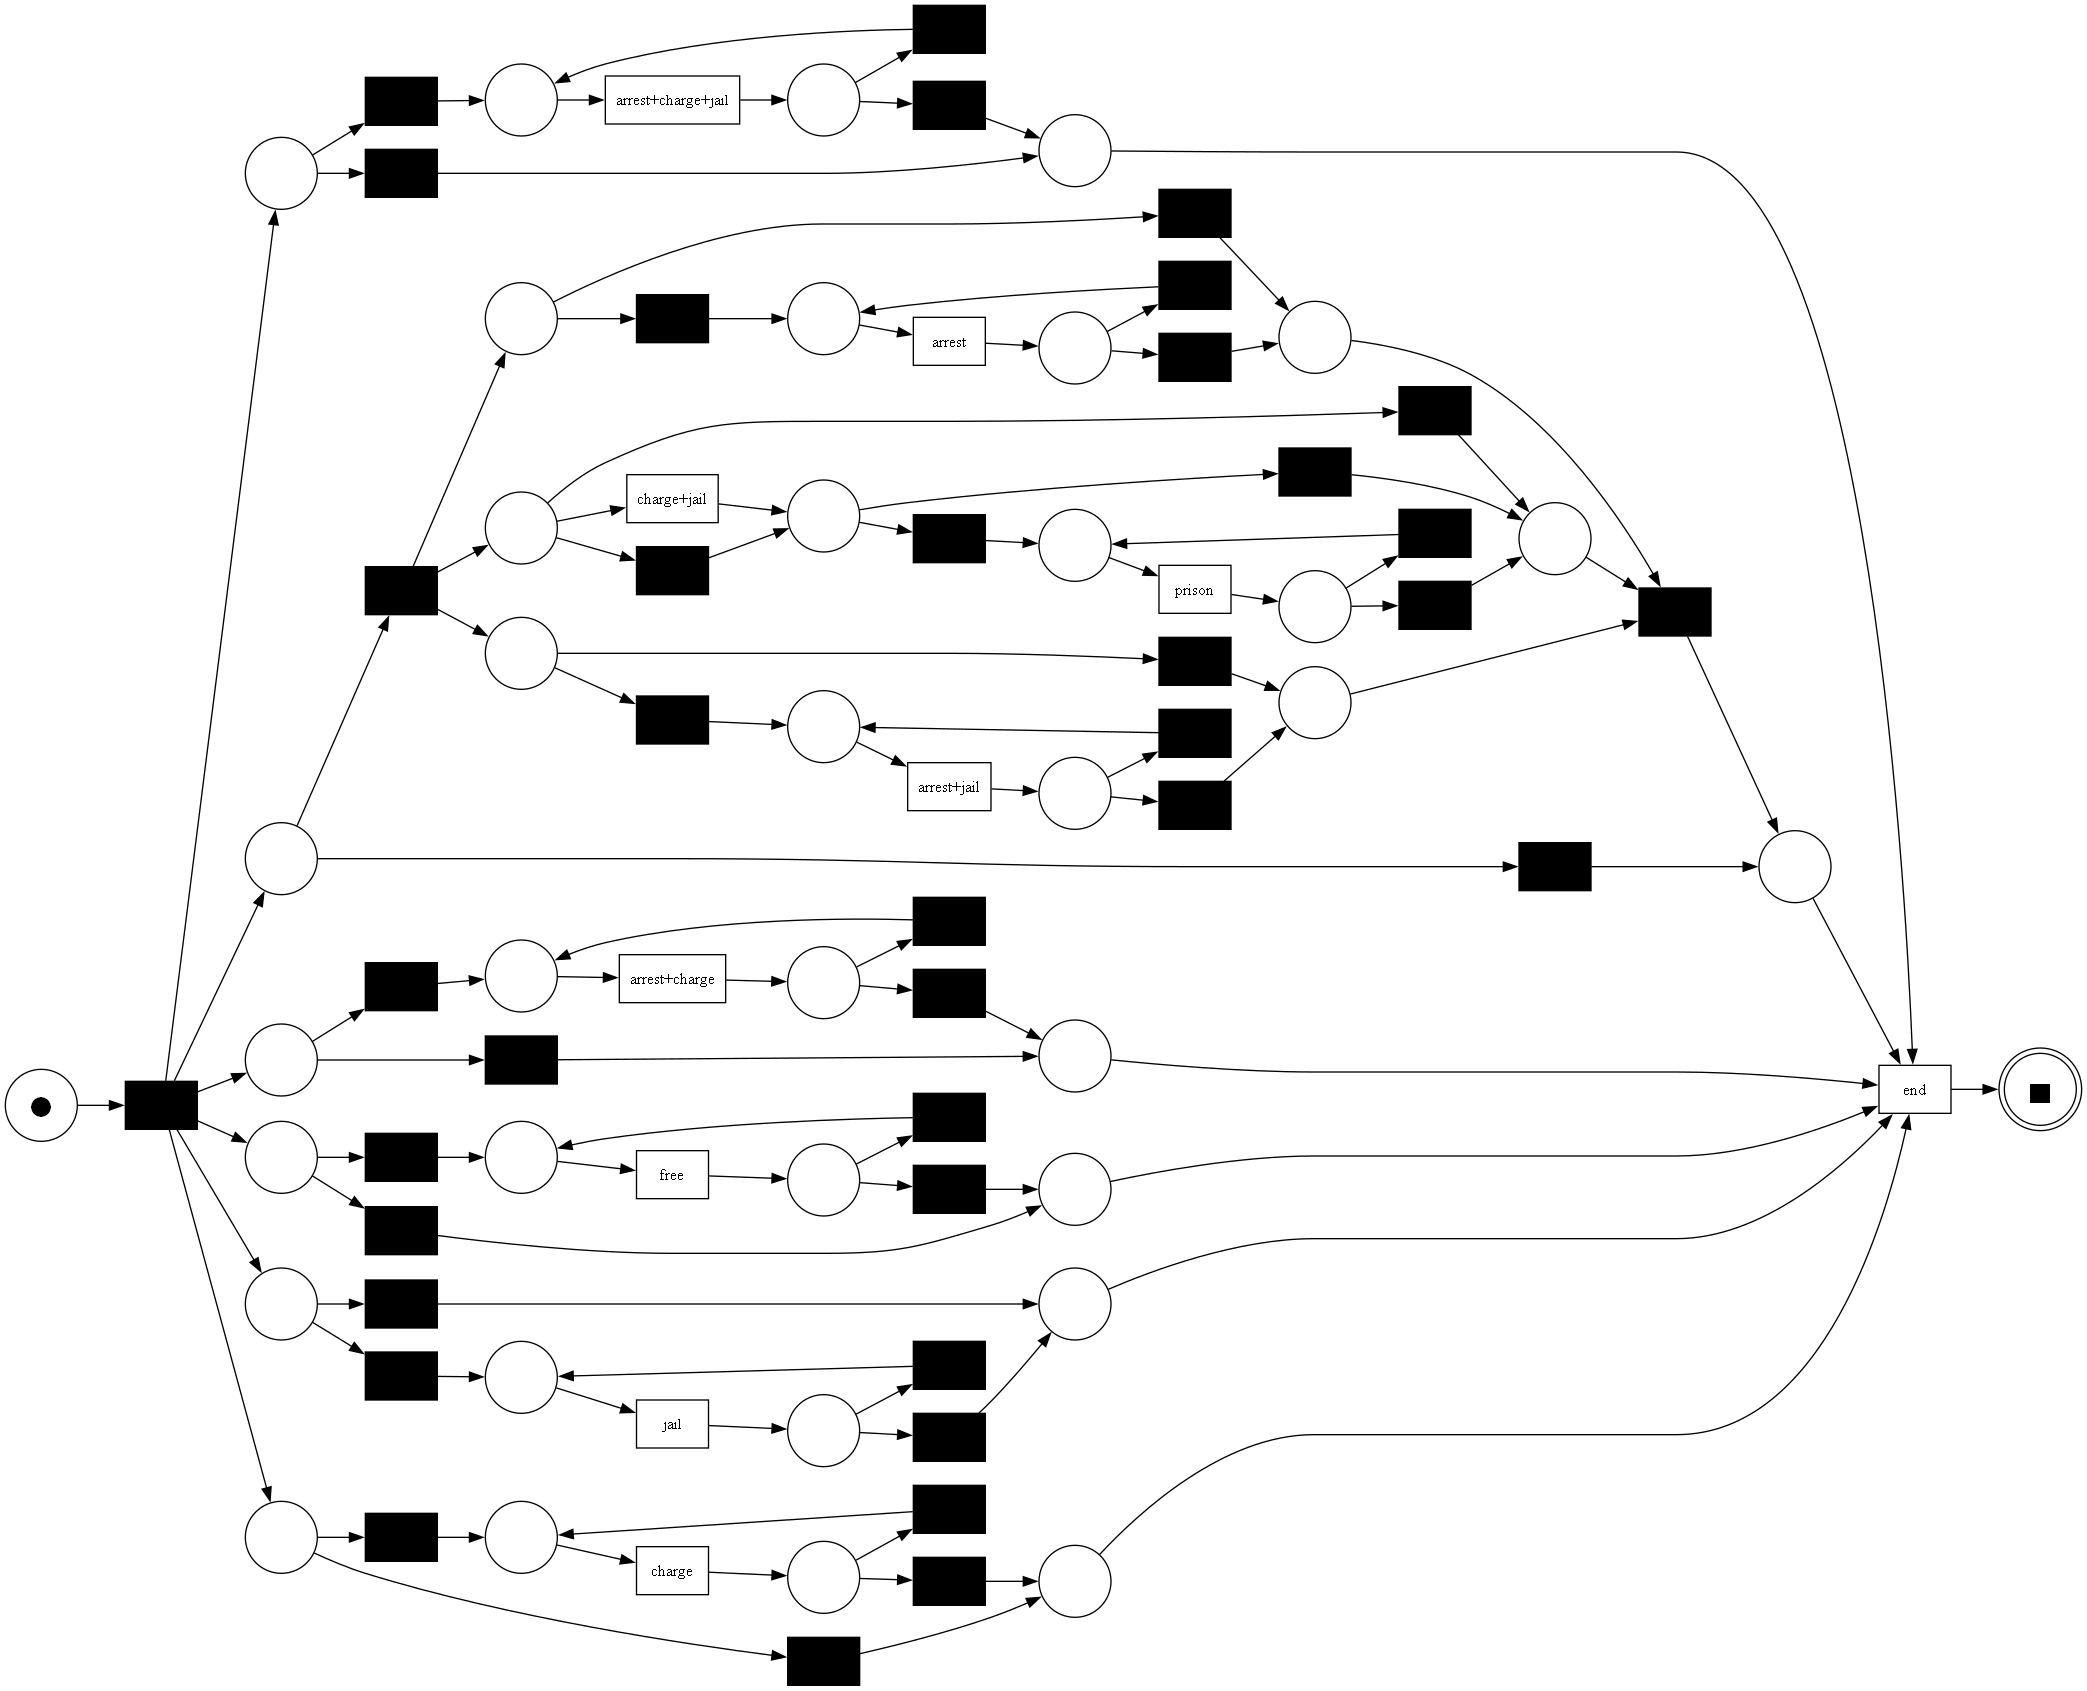

2013 | IM_noise0.2


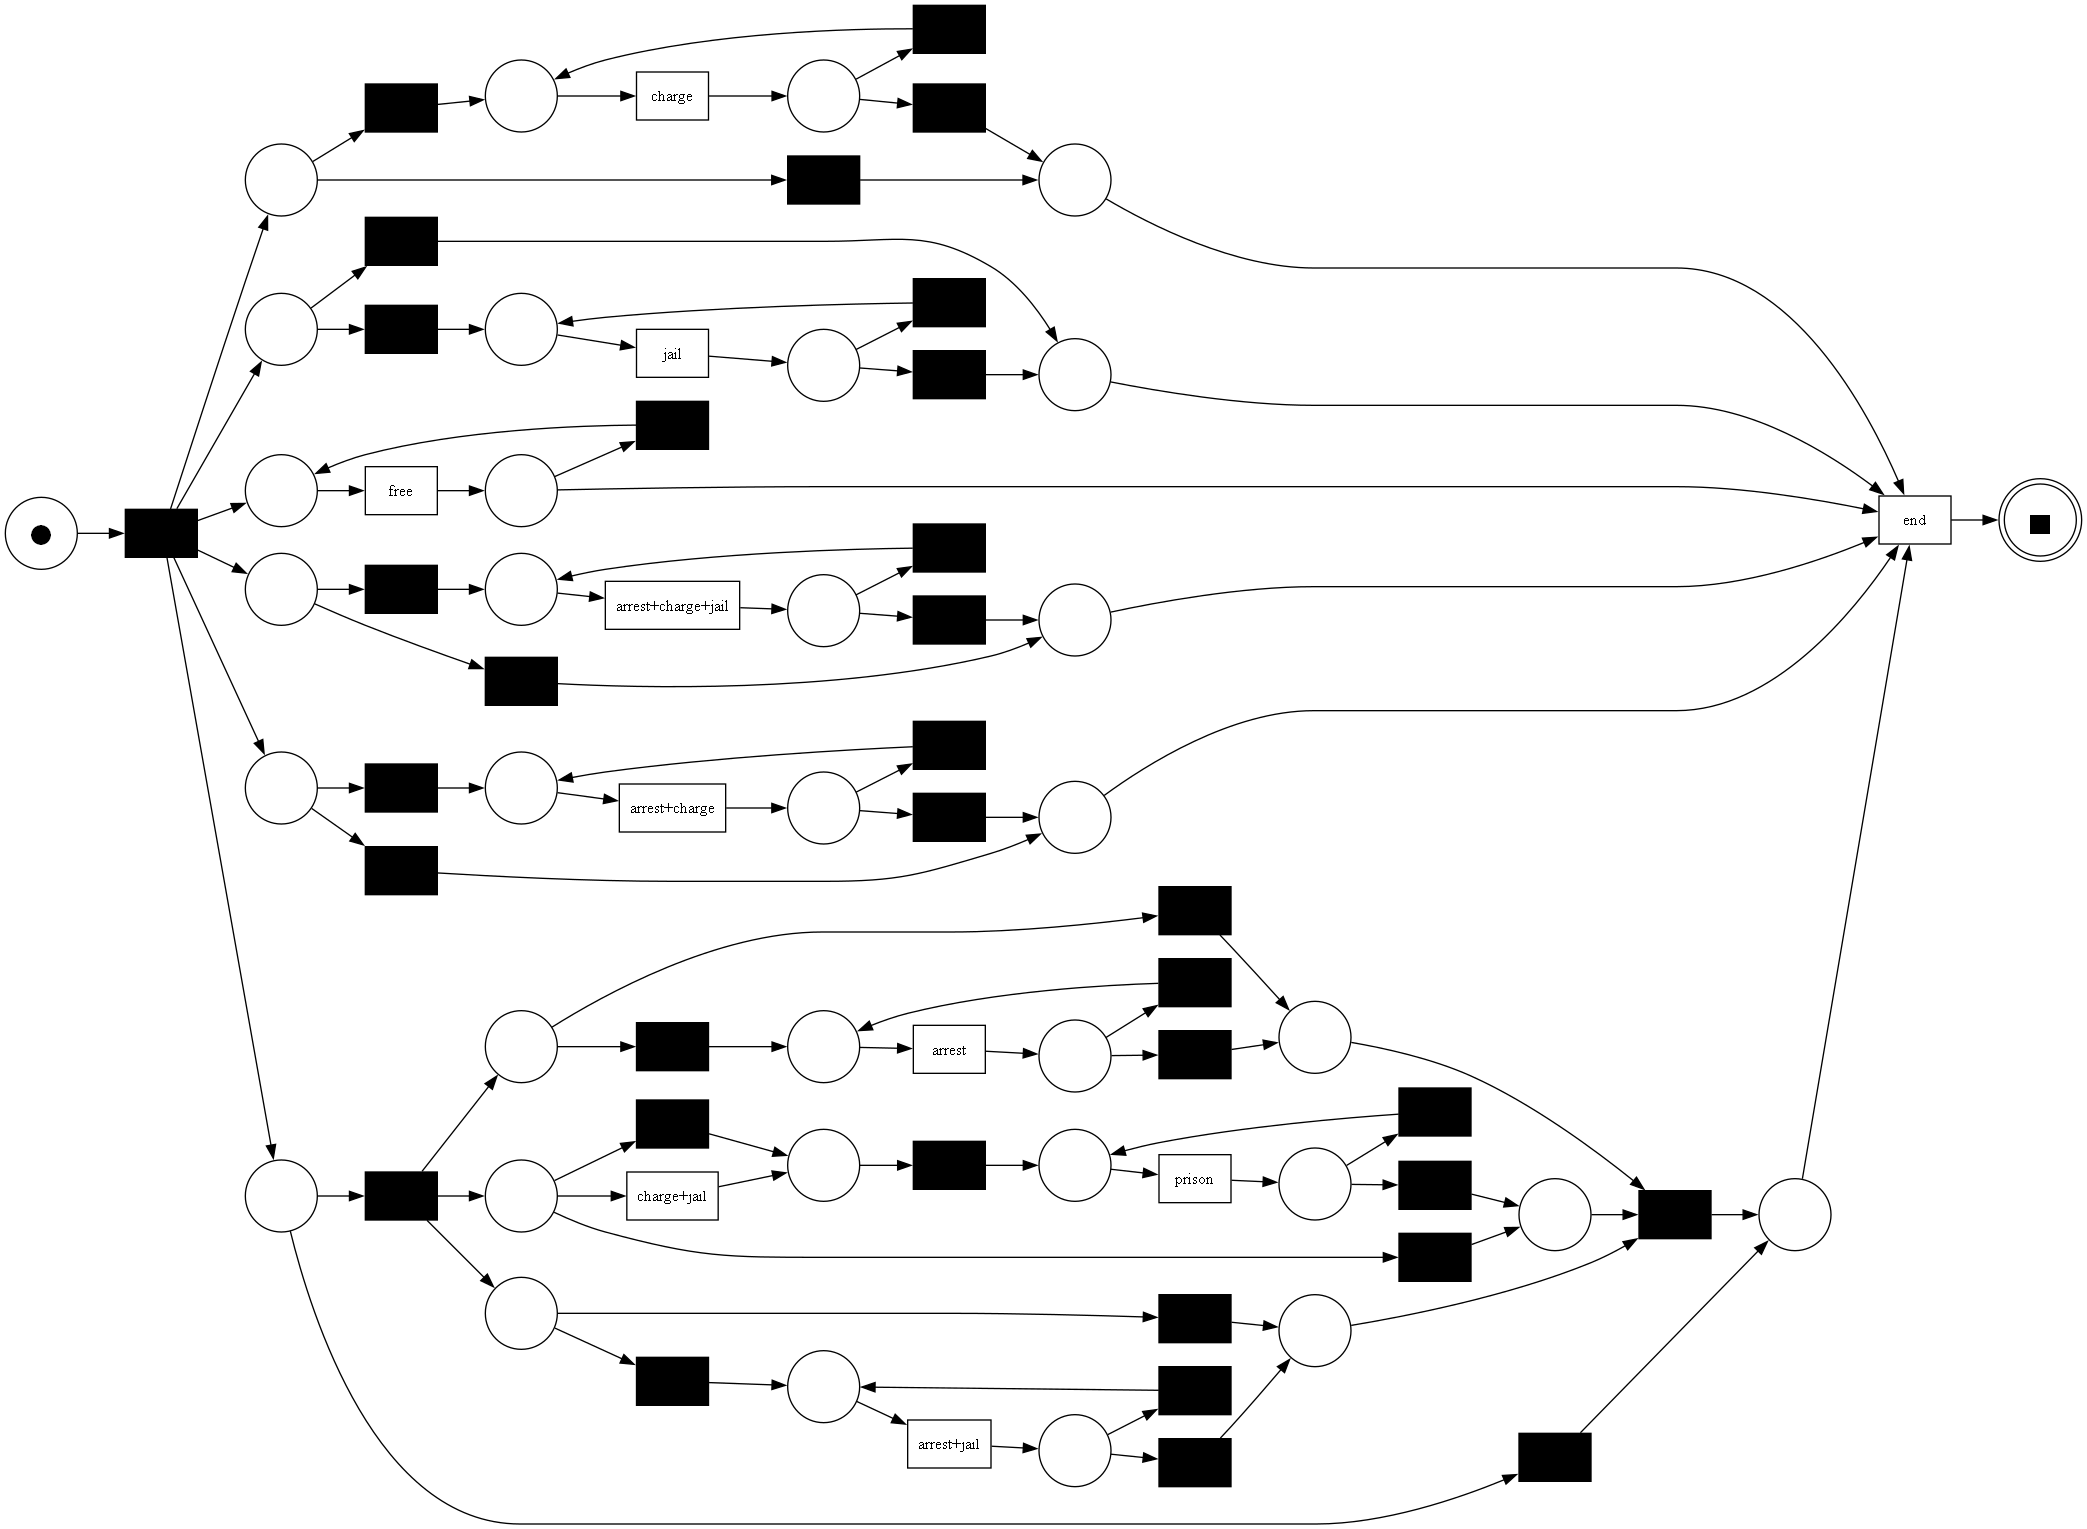

2013 | HM_dep0.9


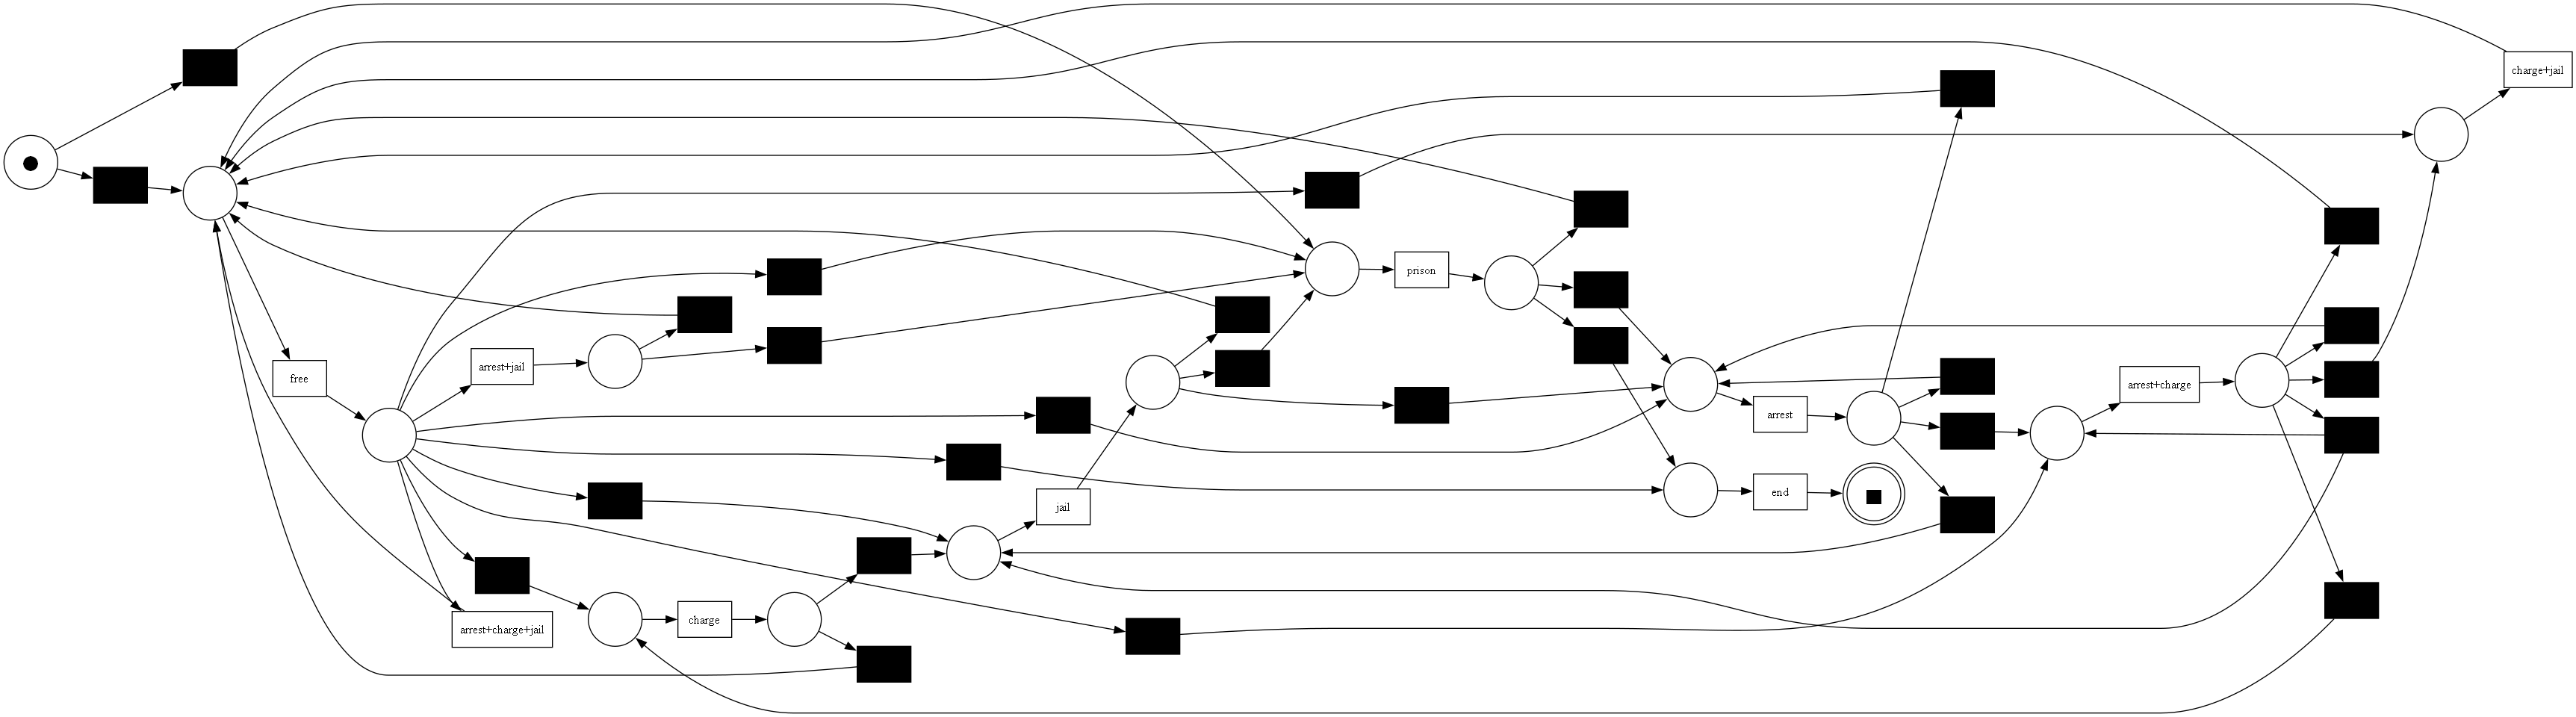

2013 | HM_dep0.95


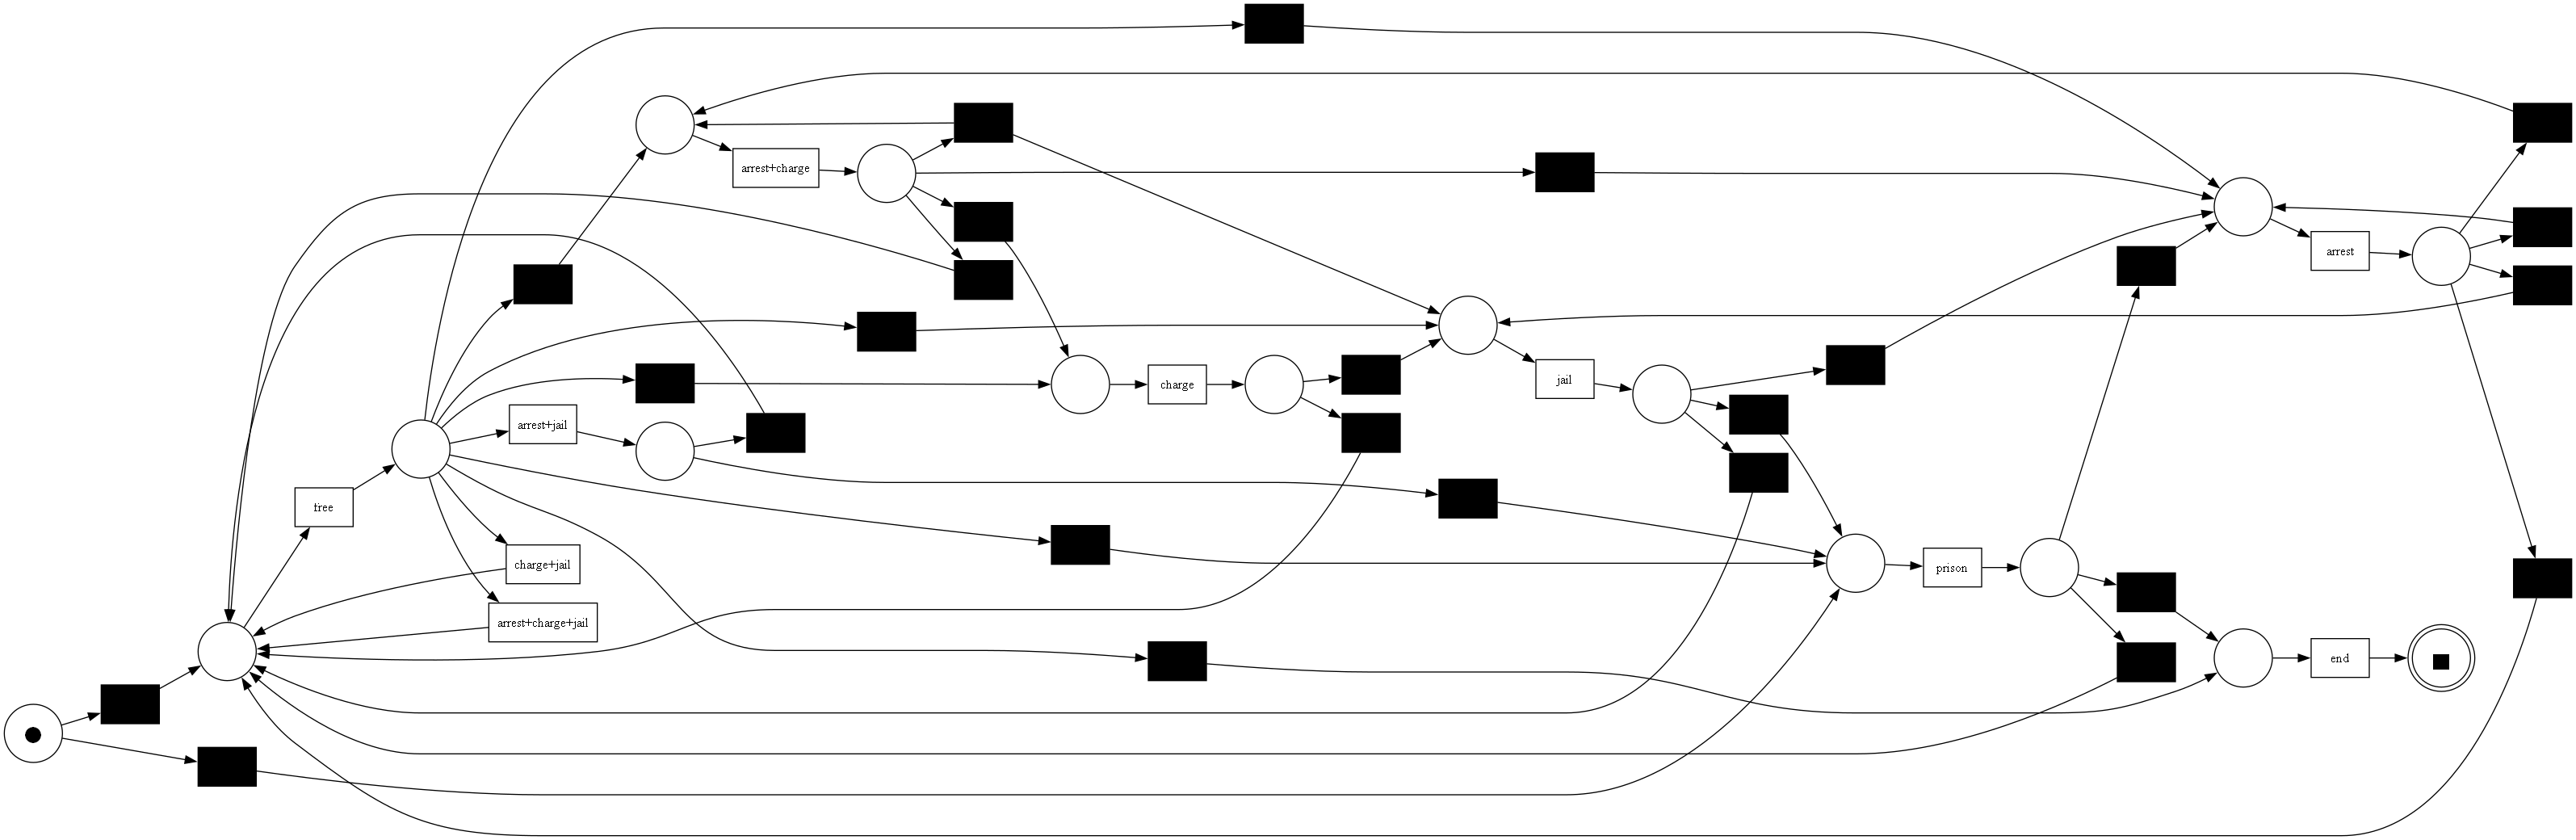

2013 | HM_dep0.99


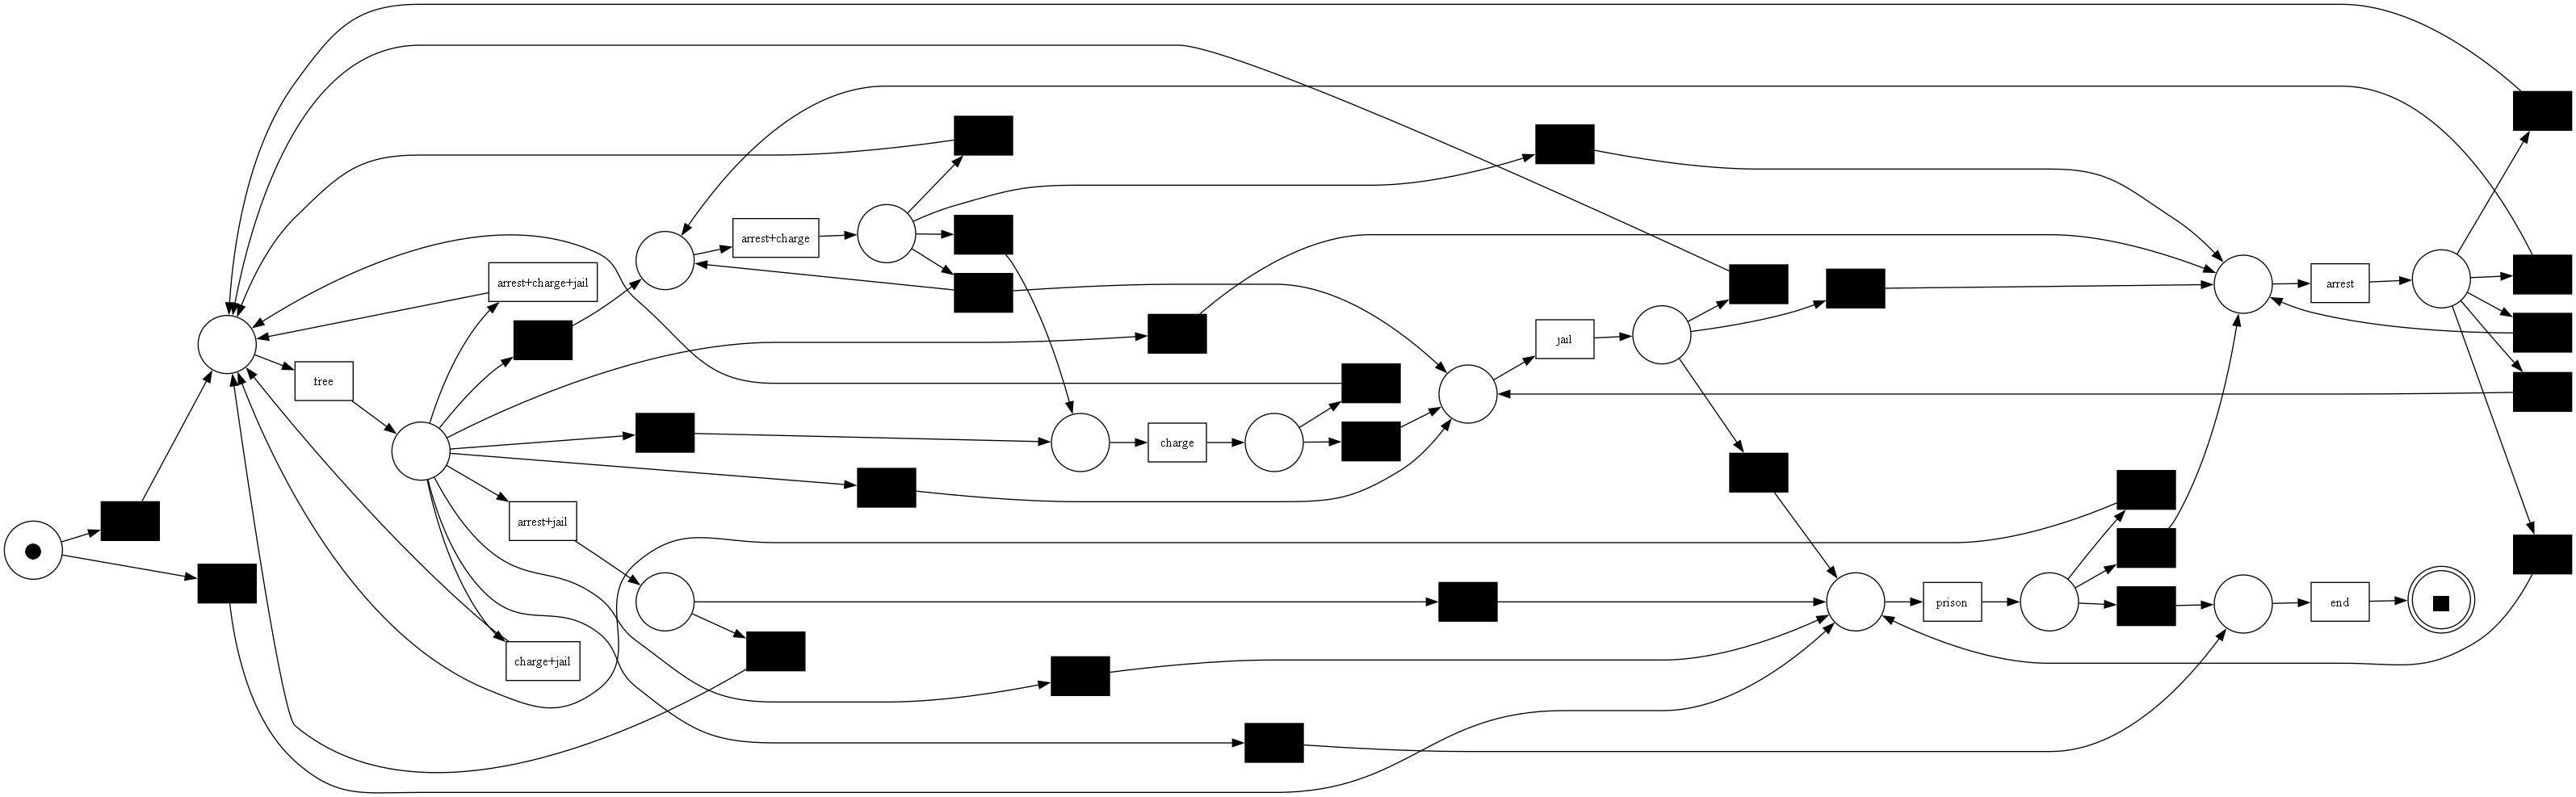

2013 | SplitMiner


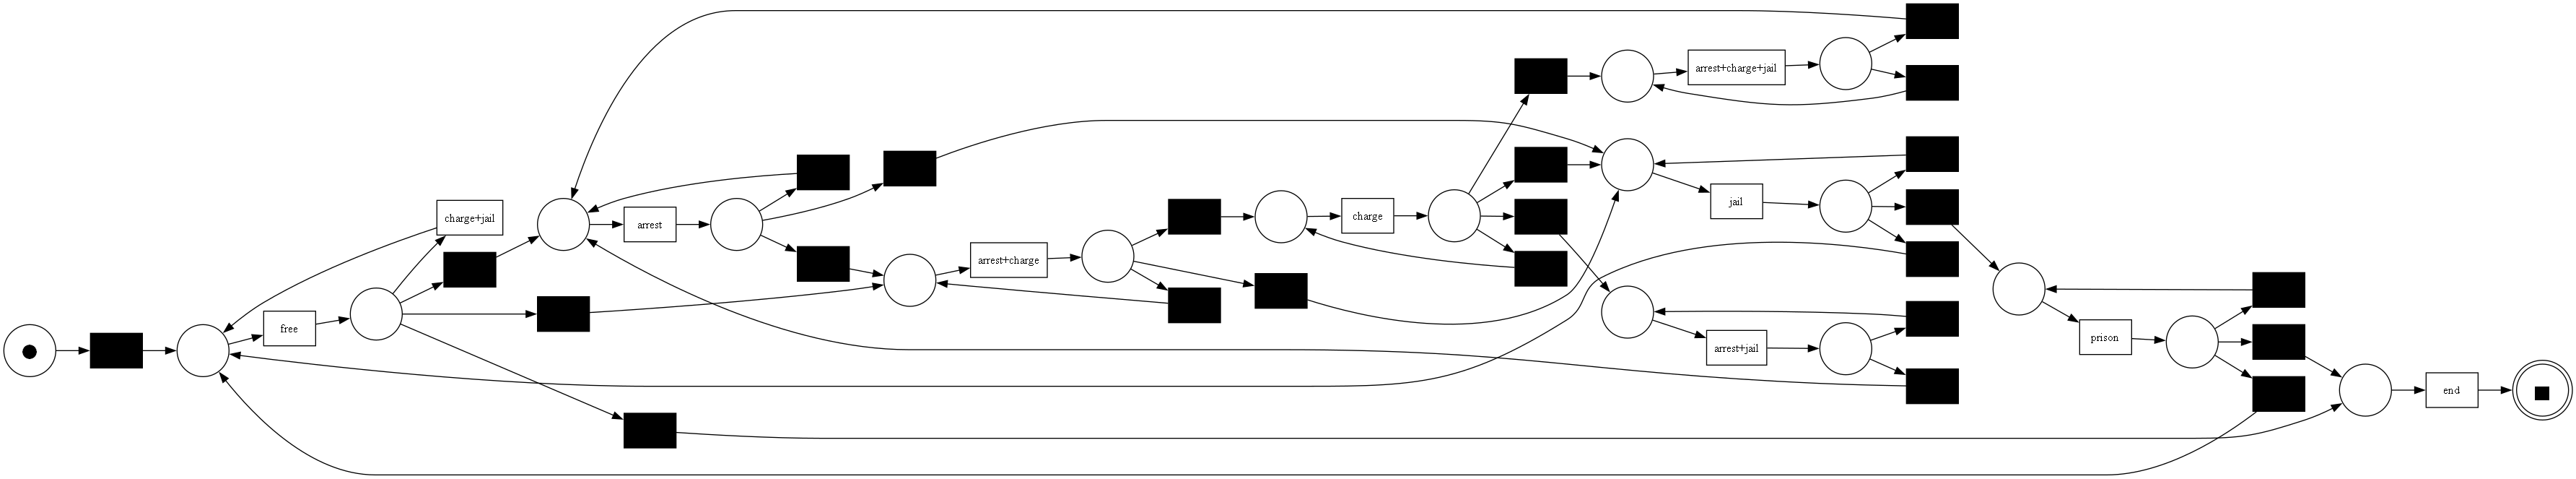

2013 | POWL


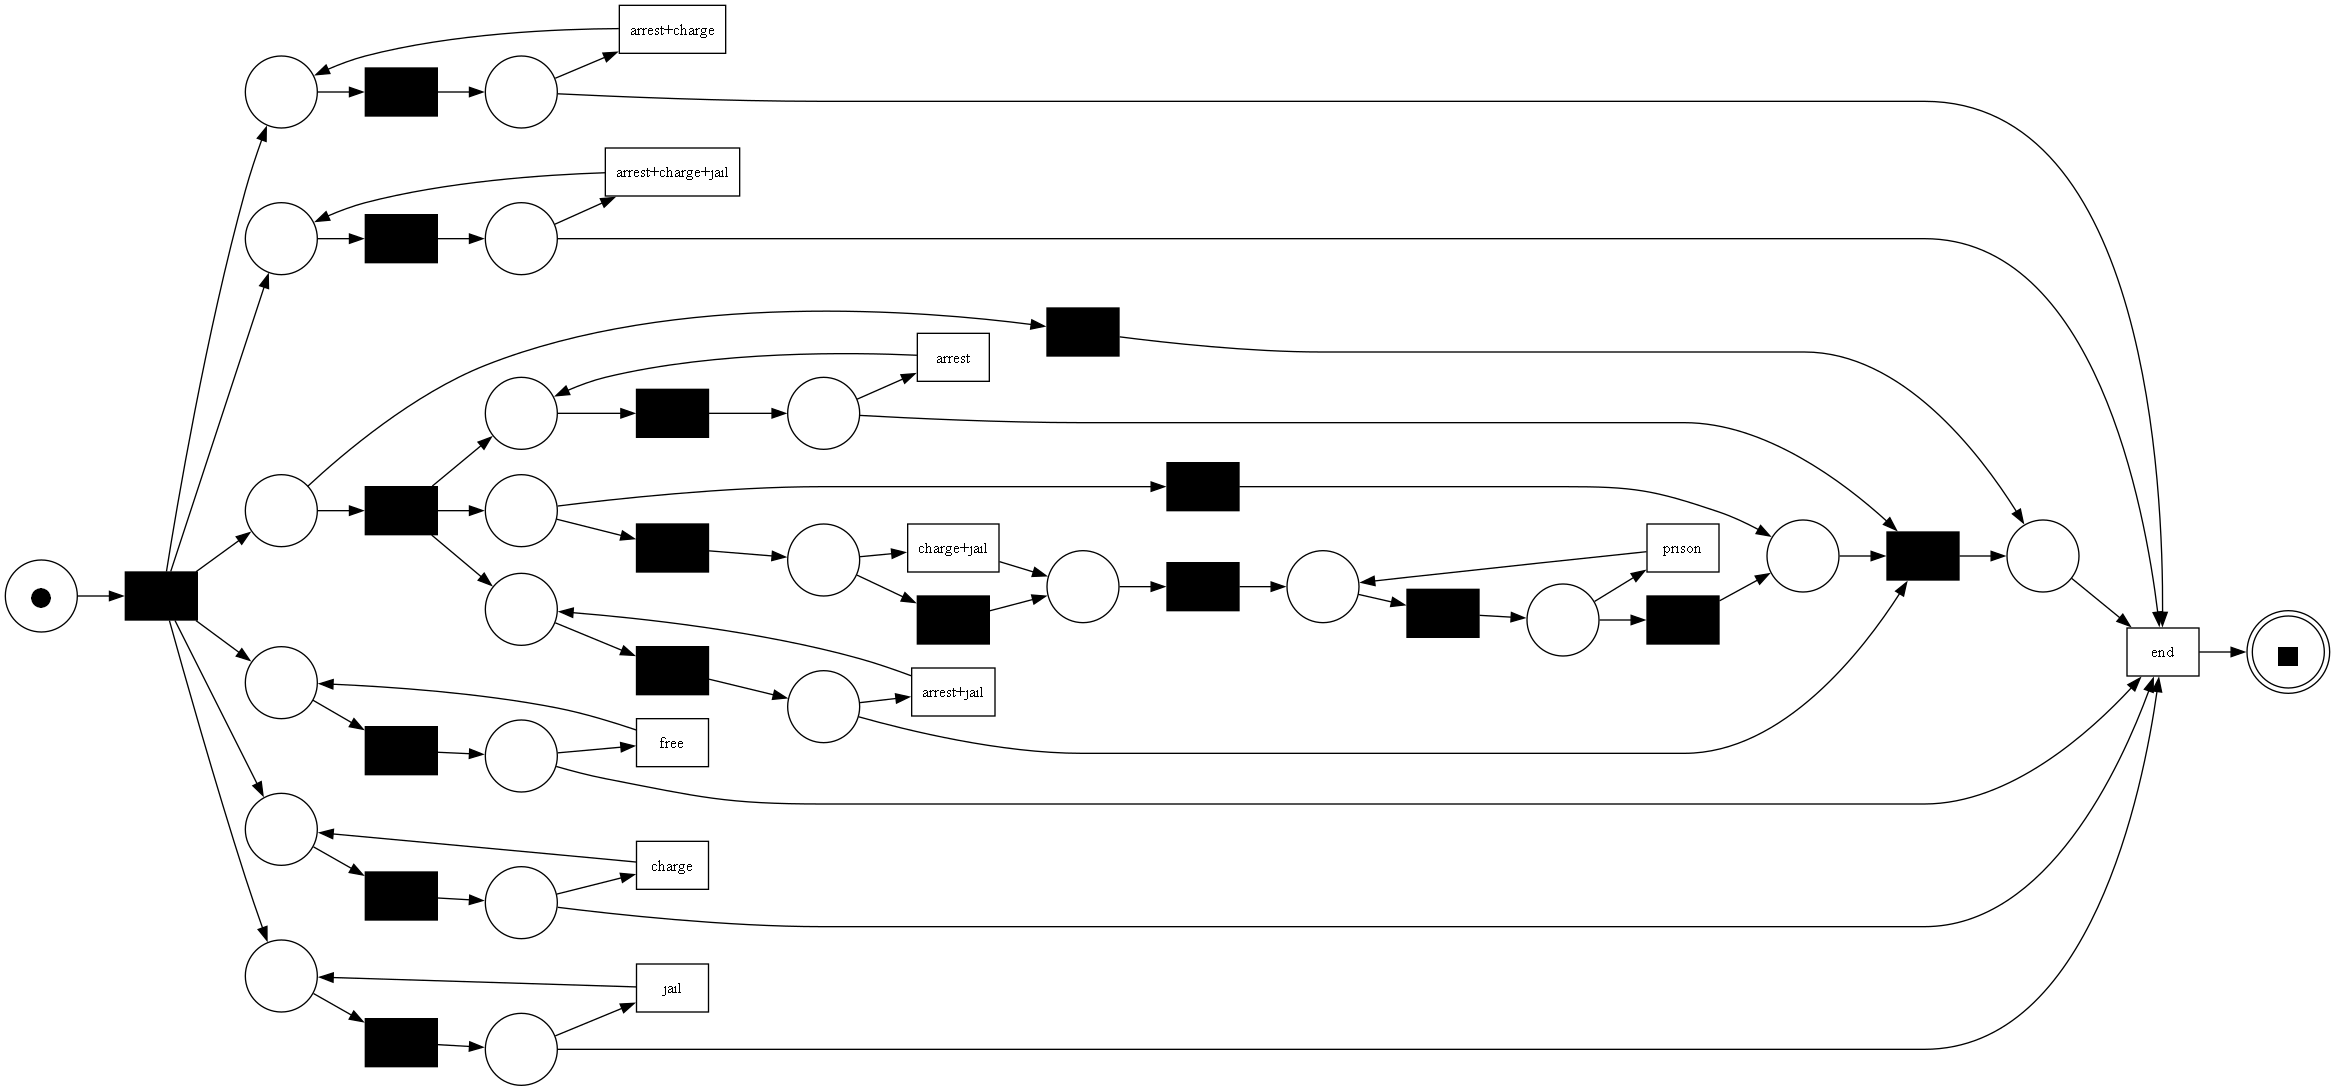

2013 | DFG_p0.0


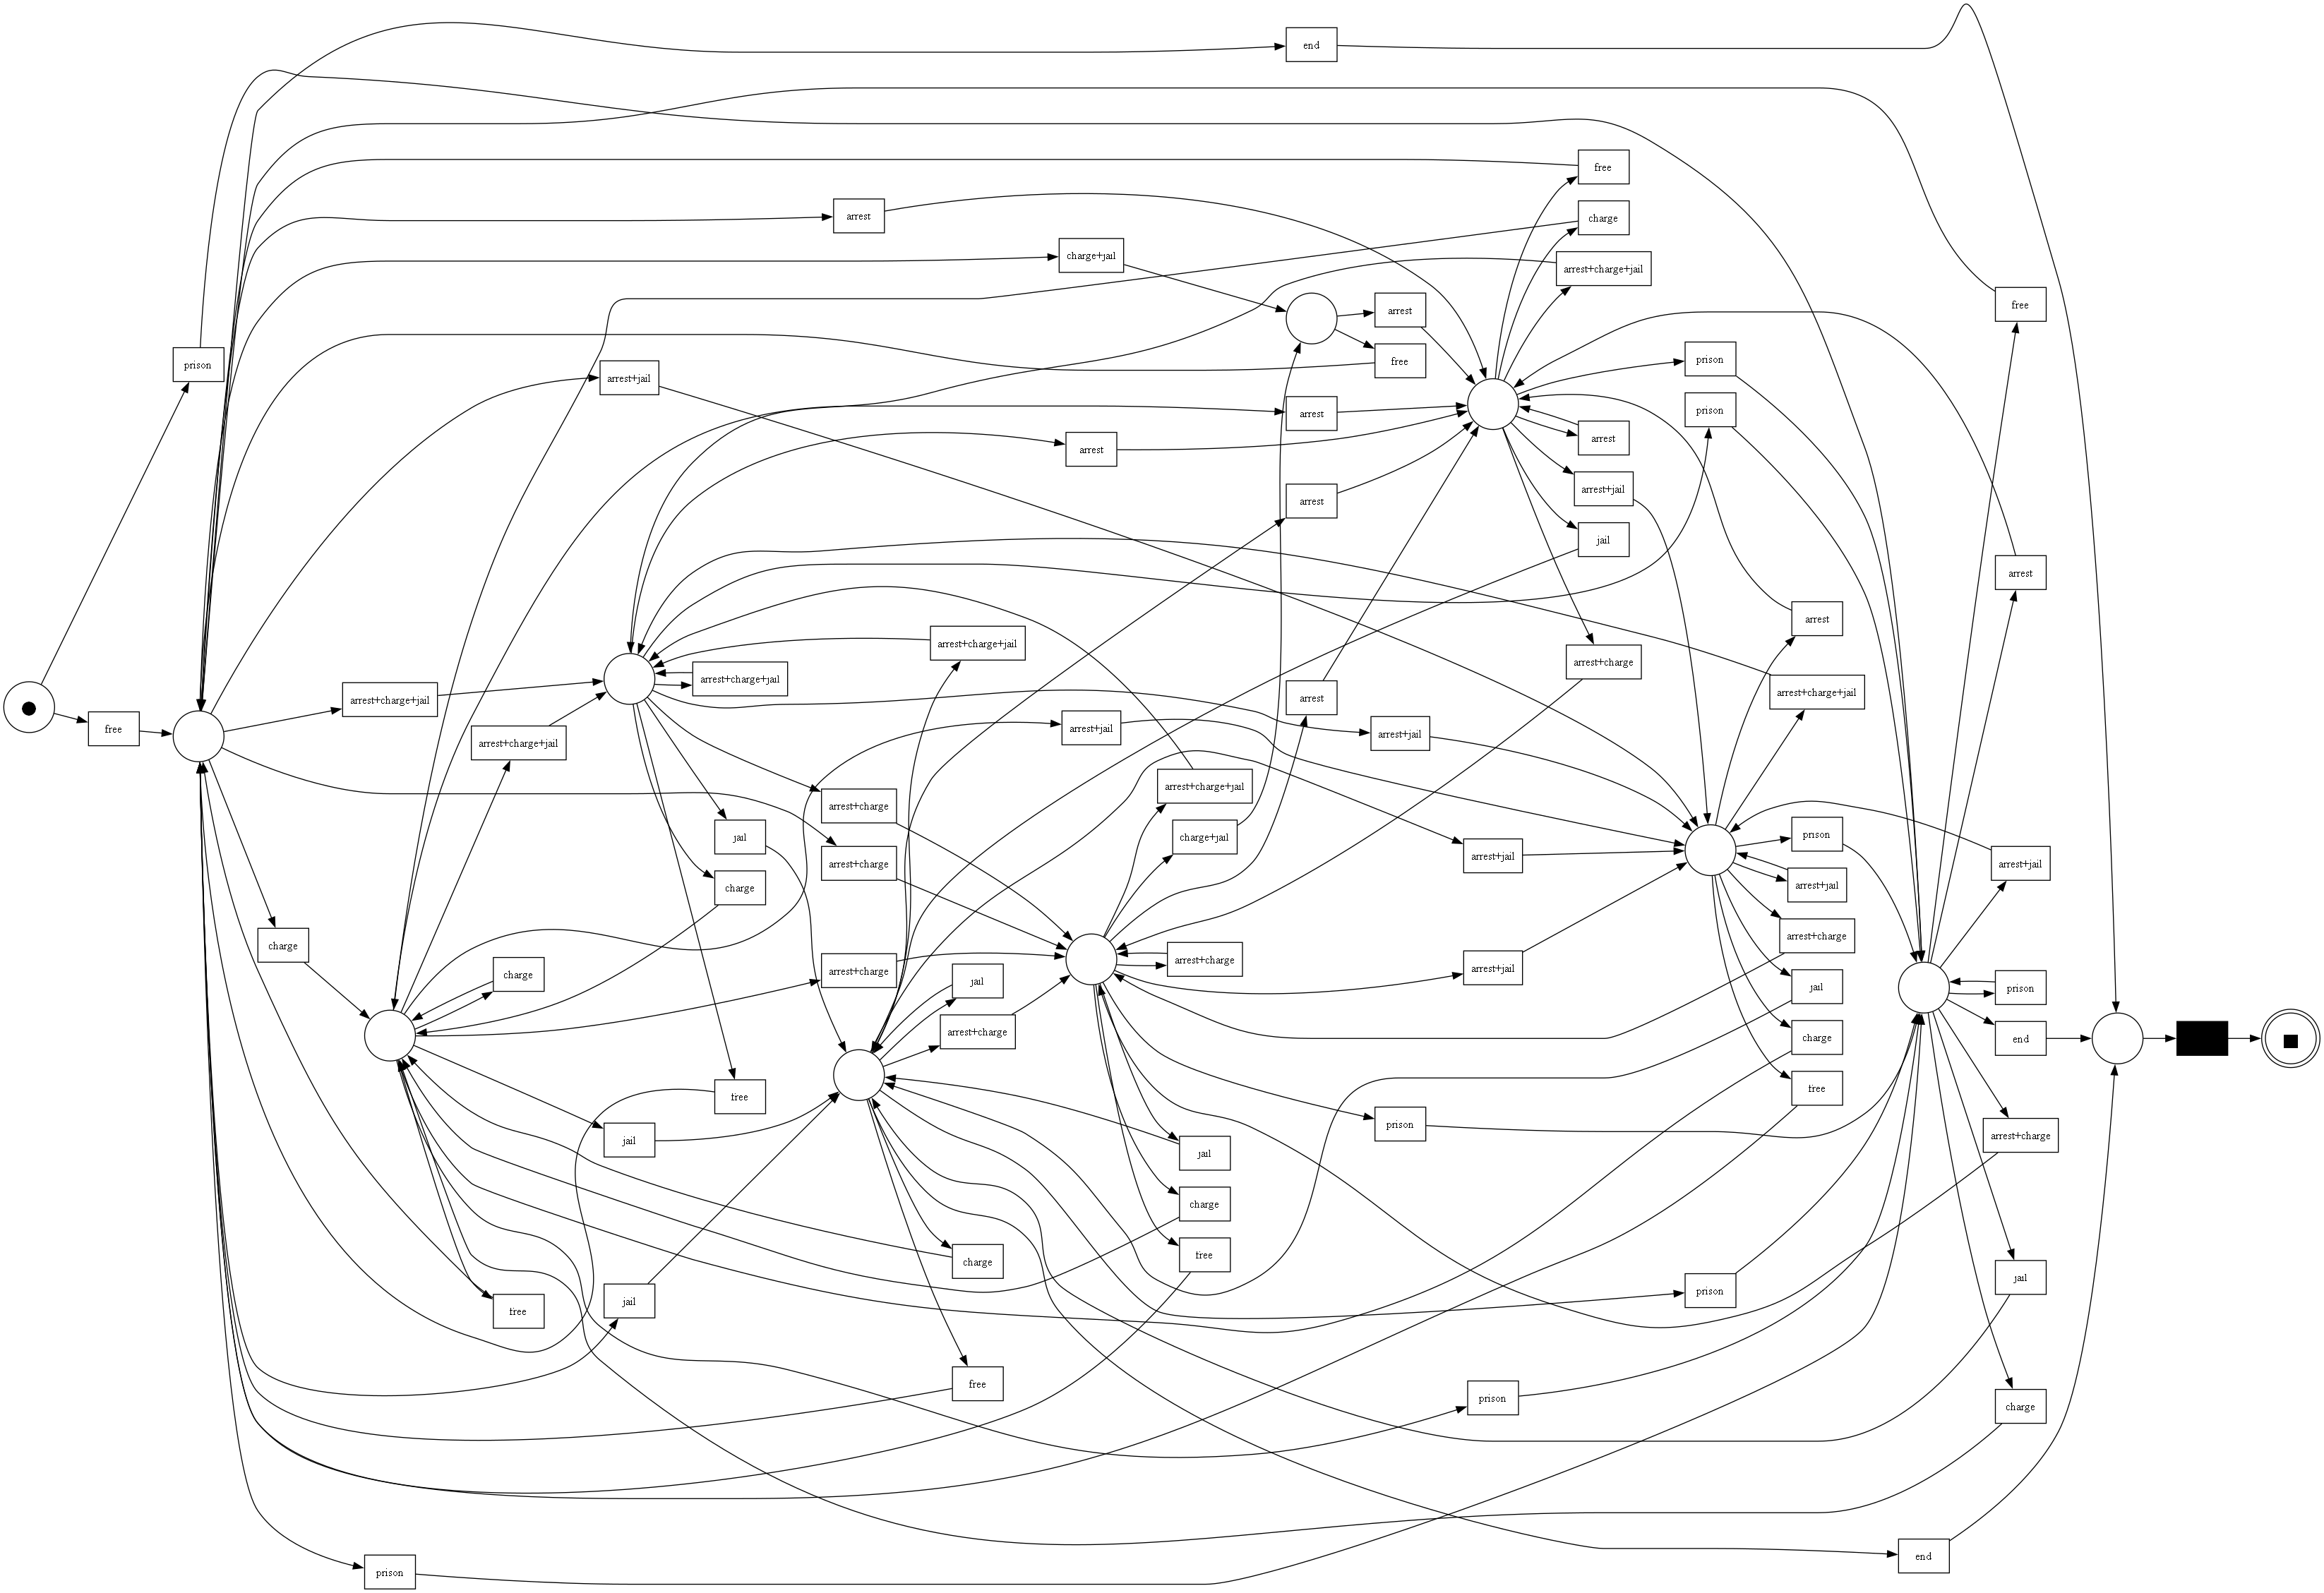

2013 | DFG_p0.05


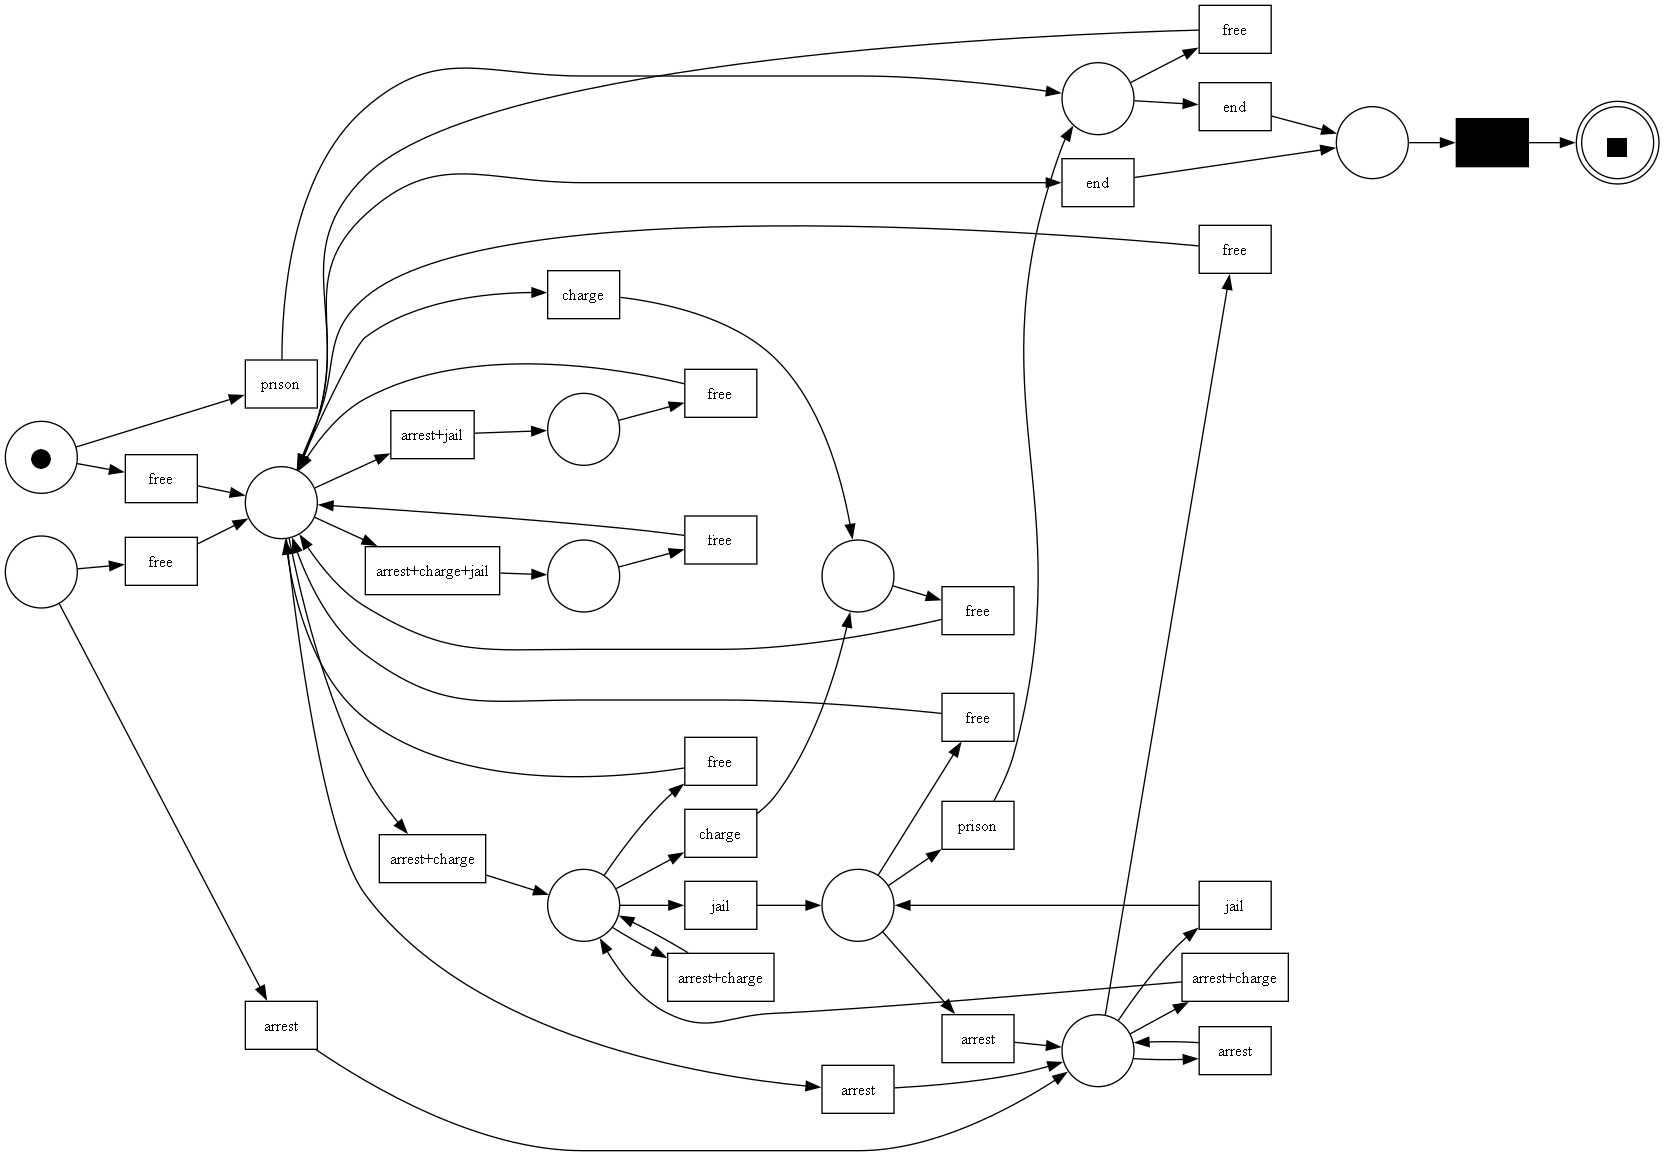

2013 | Alpha


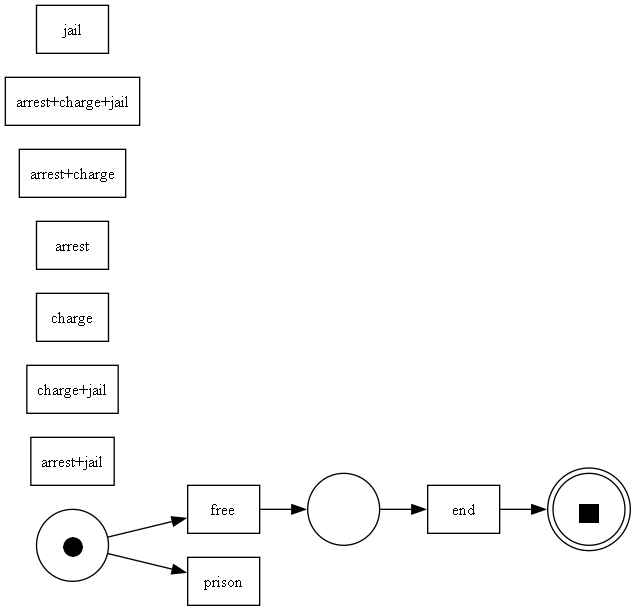

2013 | AlphaPlus


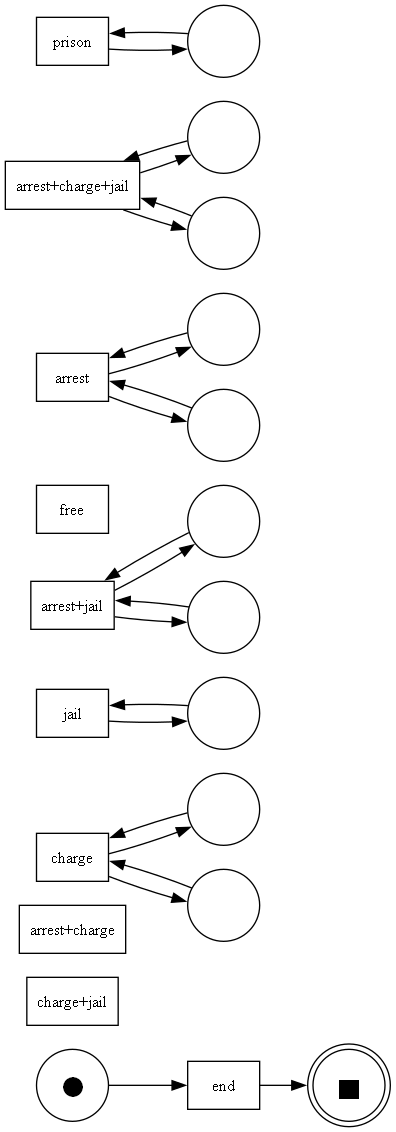

In [13]:
# рисунки сетей: out/long365_v1/net_<модель>.png
if HAS_DOT:
    for key, models in MODELS.items():
        for name, (net, im, fm) in models.items():
            if name == "flower":
                continue
            p = pp.save_net_png(net, im, fm, OUT / f"net_{name}.png")
            print(f"{key} | {name}")
            display(Image(filename=str(p), width=1000))

2013


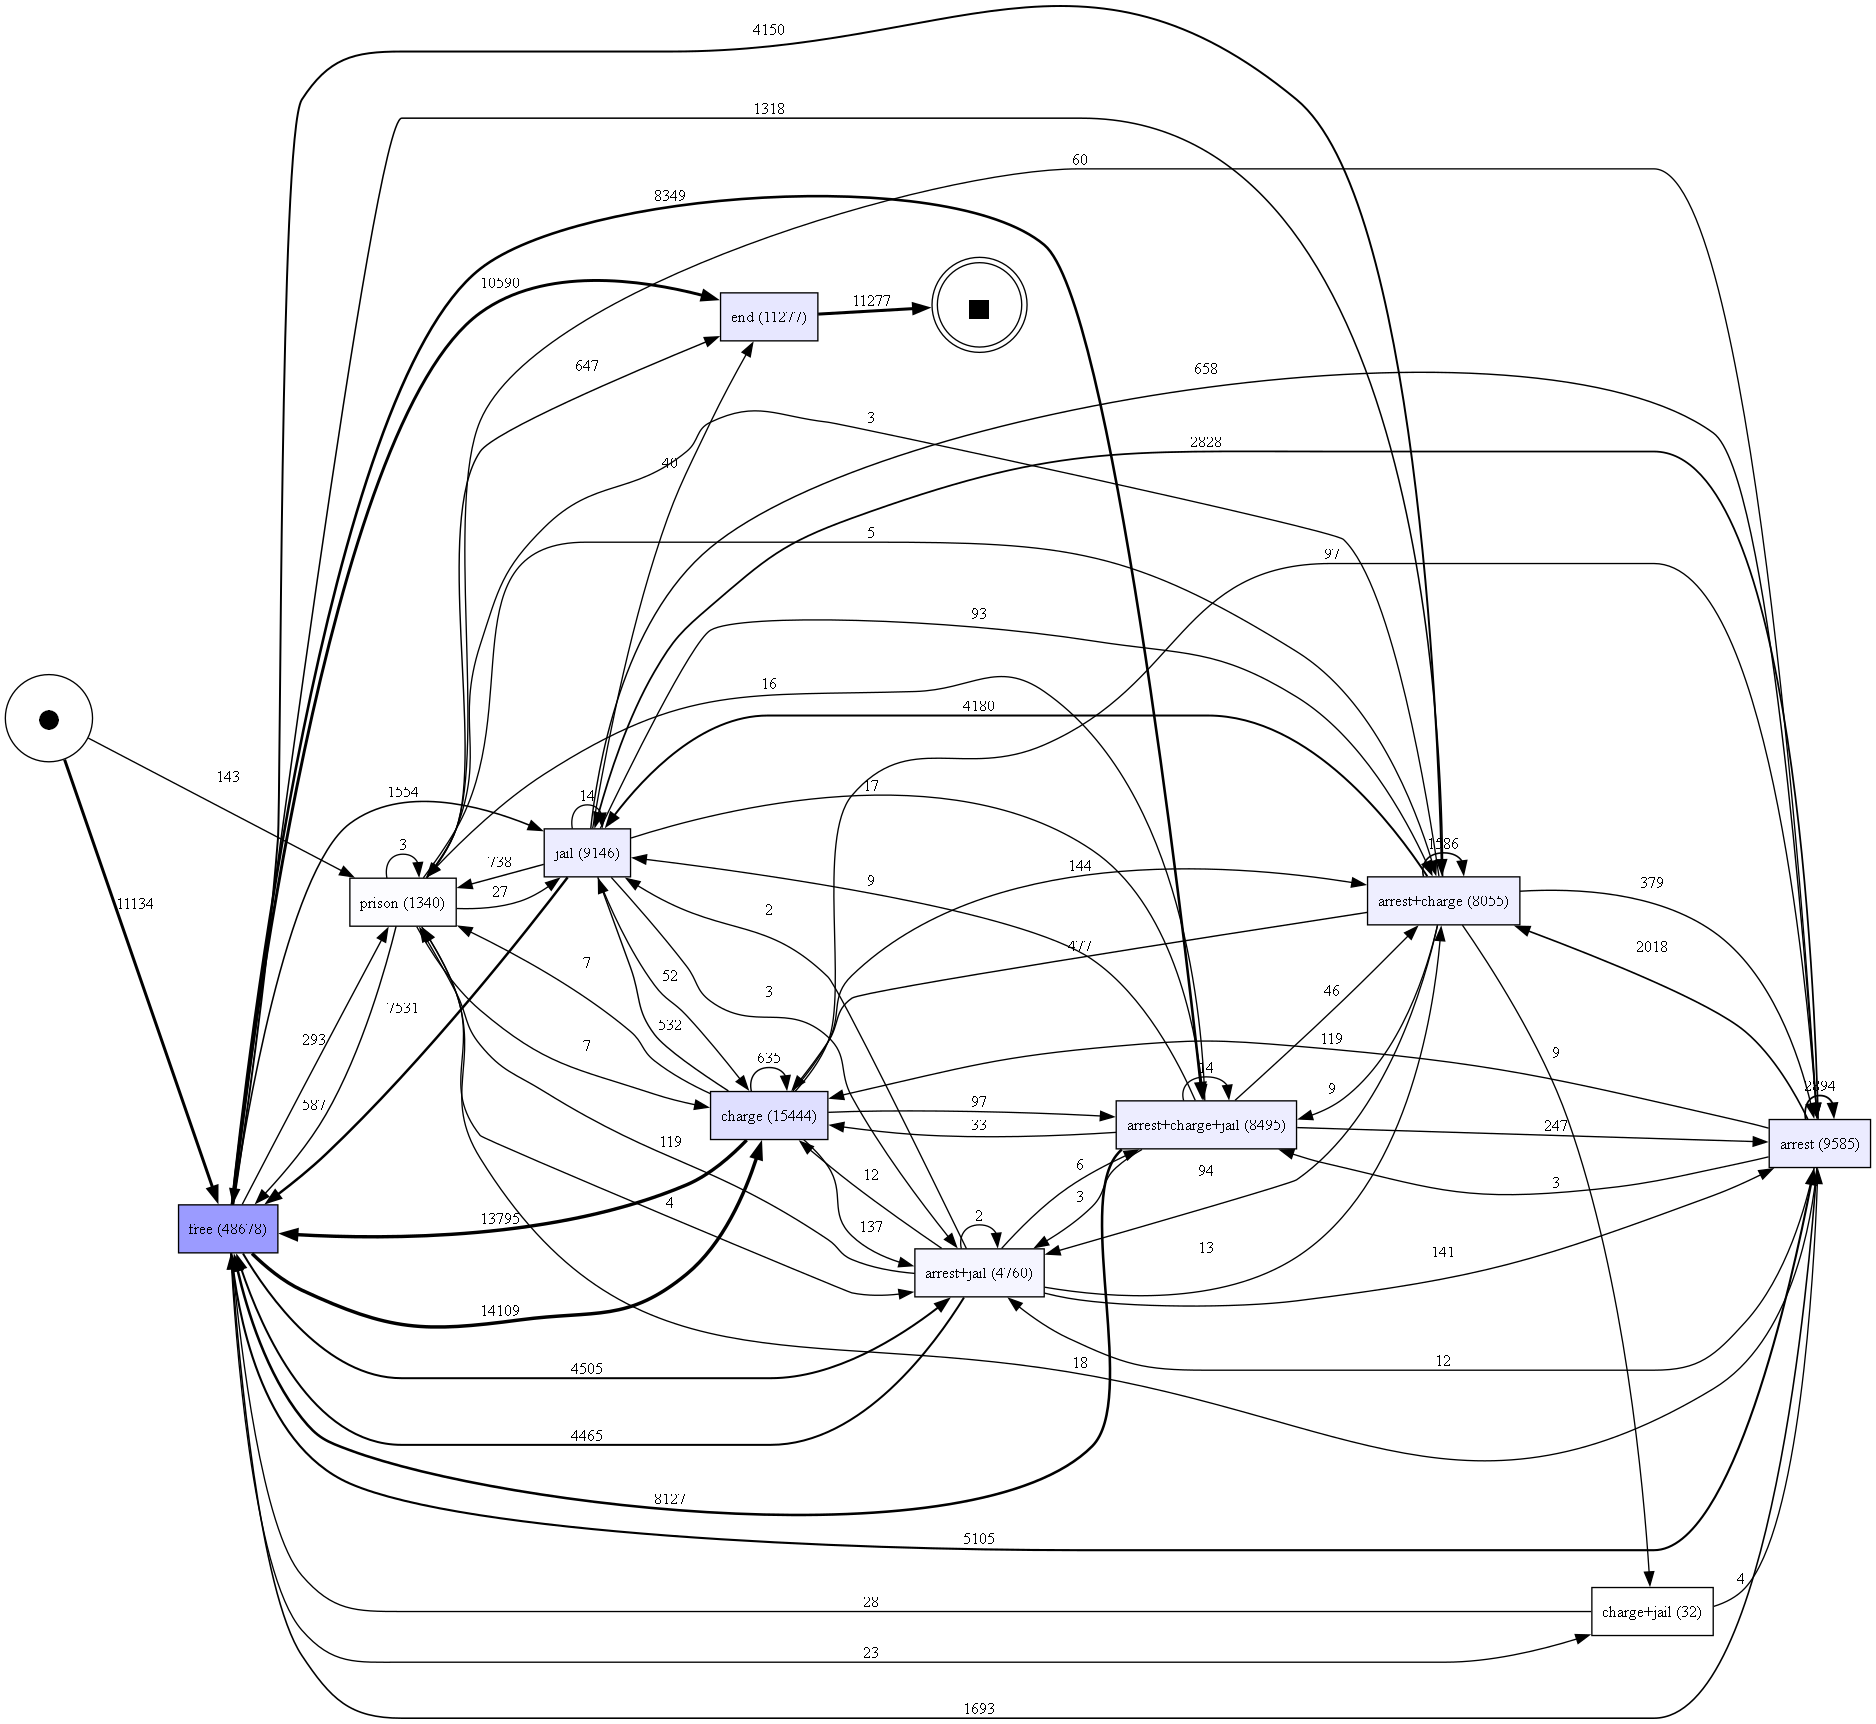

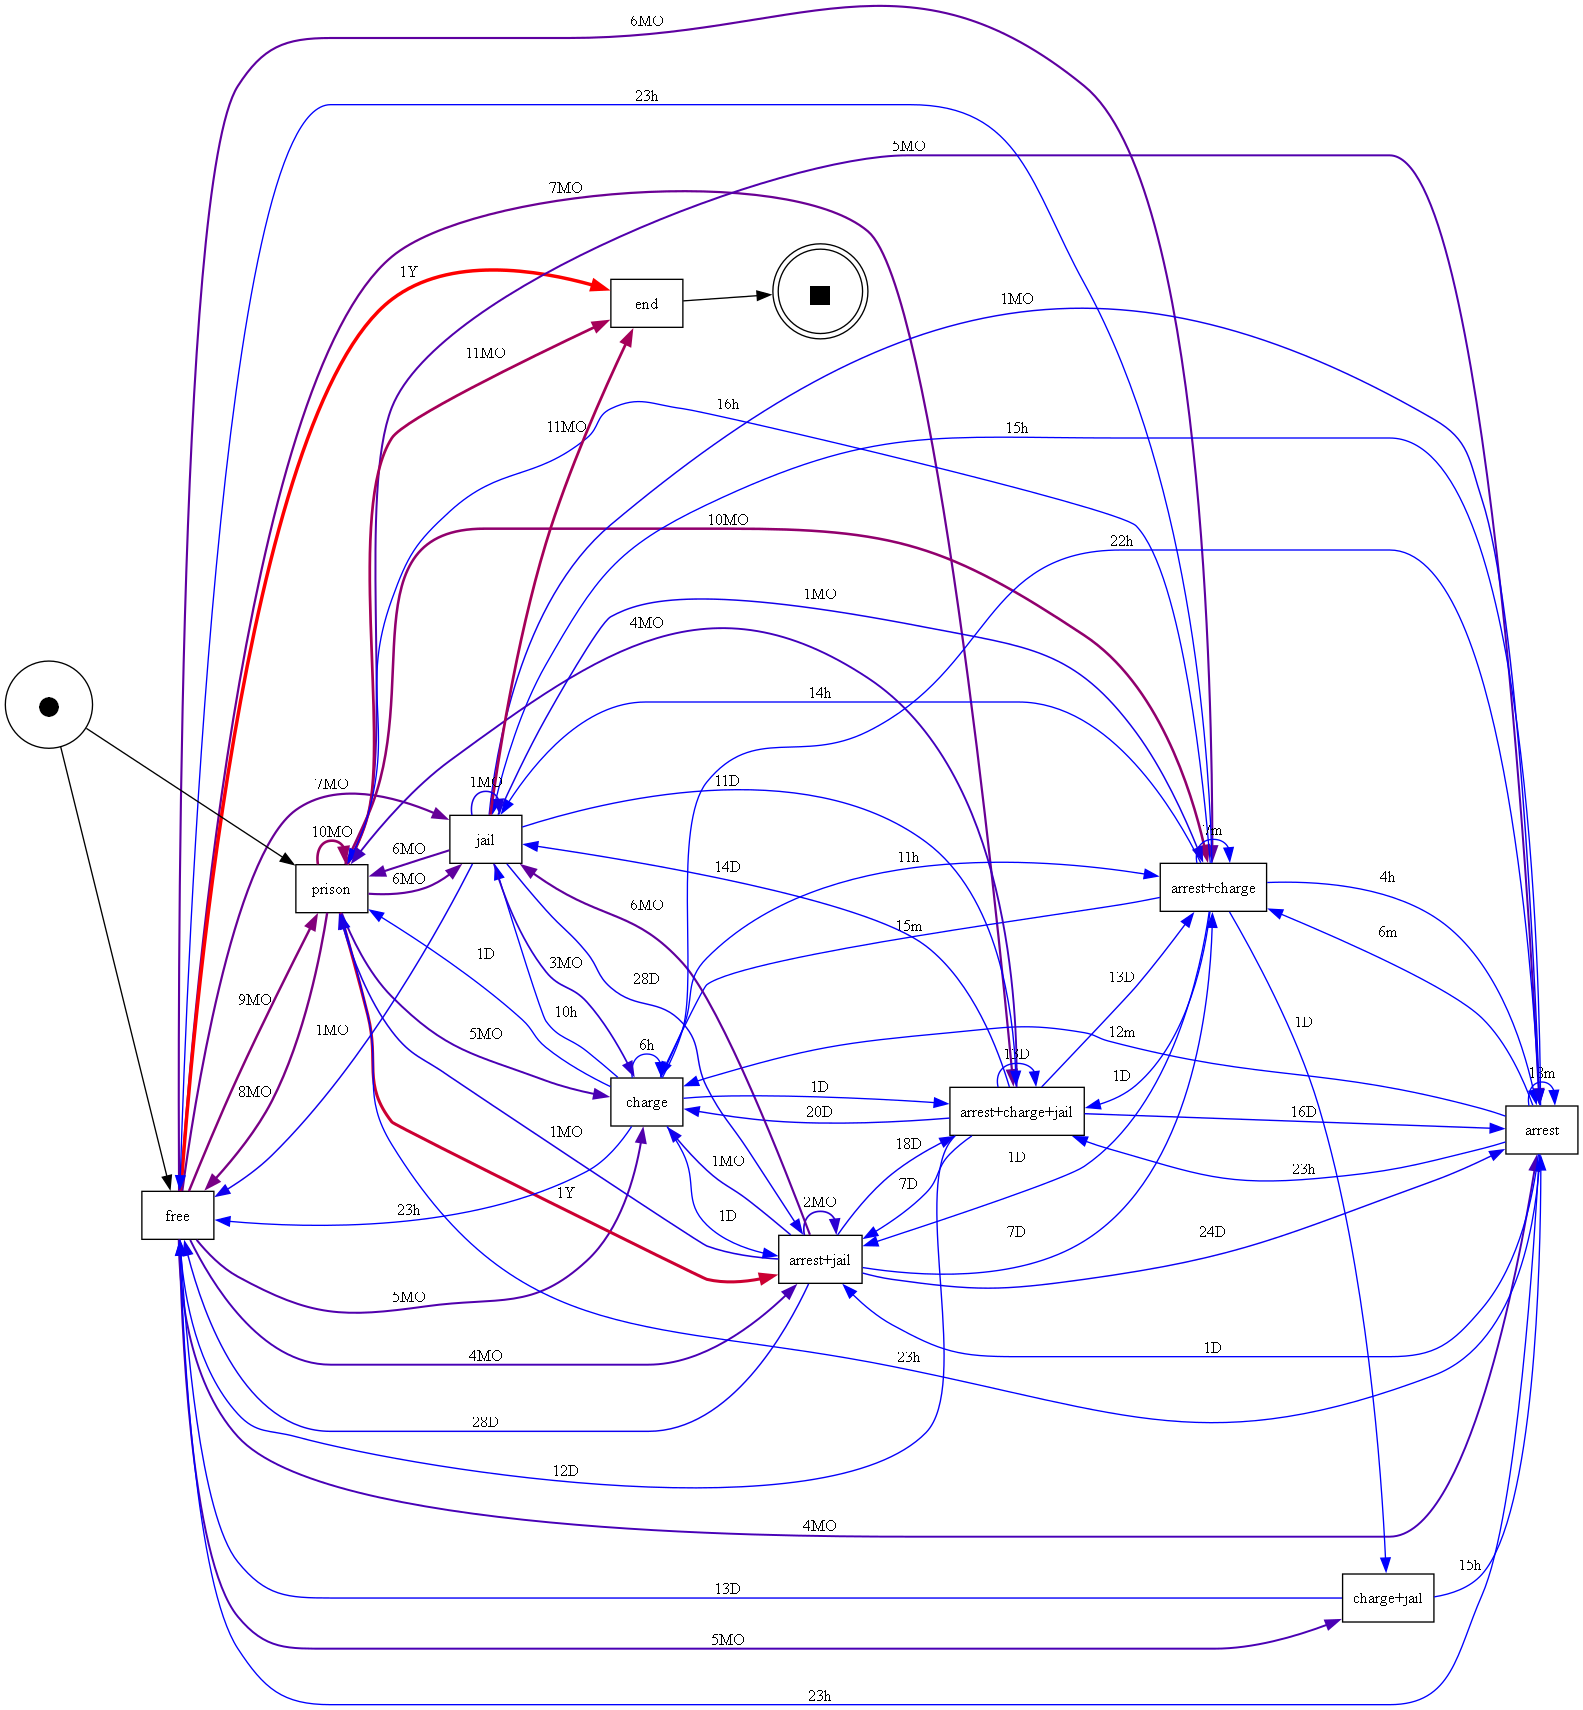

In [14]:
# DFG: частоты и среднее время переходов
if HAS_DOT:
    for key, L in LPM.items():
        print(key)
        display(Image(filename=str(pp.save_dfg_png(L, OUT / "dfg_frequency.png")), width=900))
        display(Image(filename=str(pp.save_dfg_png(L, OUT / "dfg_performance.png", performance=True)), width=900))

### 3.1. Fitness и precision (весь журнал)

In [15]:
from eval_resumable import evaluate_full_resumable

qs = []
for key in LOGS:
    f = OUT / "model_quality.csv"
    if RUN_EVAL or not f.exists():
        t0 = time.time()
        q = evaluate_full_resumable(MODELS[key], LPM[key], OUT / "model_quality_ckpt.jsonl")
        q.to_csv(f, index=False)
        print(f"{key}: {(time.time() - t0) / 60:.1f} мин")
    else:
        q = pd.read_csv(f)
    qs.append(q.assign(experiment=key))
quality = pd.concat(qs, ignore_index=True)
cols = ["experiment", "model", "fitness_tbr", "pct_fit_traces_tbr", "precision_etc", "precision_flower",
        "precision_norm", "f1", "places", "transitions", "silent"]
quality[[c for c in cols if c in quality]].round(3).set_index(["experiment", "model"])

replaying log with TBR, completed traces ::   0%|          | 0/4754 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/33797 [00:00<?, ?it/s]

IM_noise0.0  full  fitness_tbr=1.0000 precision=0.4360 align=nan


replaying log with TBR, completed traces ::   0%|          | 0/4754 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/33797 [00:00<?, ?it/s]

IM_noise0.2  full  fitness_tbr=0.9999 precision=0.4417 align=nan


... (28 outputs left out)

replaying log with TBR, completed traces ::   0%|          | 0/33797 [00:00<?, ?it/s]

flower       full  fitness_tbr=1.0000 precision=0.4206 align=nan


2013: 12.5 мин


fitness_tbr  pct_fit_traces_tbr  precision_etc  precision_flower  precision_norm     f1  places  transitions  silent
experiment model                                                                                                                            
2013       IM_noise0.0        1.000             100.000          0.436             0.421           0.026  0.607      37           48      38
           IM_noise0.2        1.000              99.725          0.442             0.421           0.036  0.613      35           44      34
           HM_dep0.9          0.982              60.938          0.670             0.421           0.430  0.796      17           38      28
           HM_dep0.95         0.982              60.903          0.675             0.421           0.439  0.800      16           36      26
           HM_dep0.99         0.982              60.956          0.668             0.421           0.427  0.795      16           37      27
           SplitMiner         0.772               6.394          0.813             0.421           0.678  0.792      19           34      24
           POWL               1.000             100.000          0.422             0.421           0.003  0.594      24           27      17
           DFG_p0.0           1.000             100.000          0.527             0.421           0.183  0.690      12           72       1
           DFG_p0.05          0.967              69.806          0.815             0.421           0.681  0.885      12           27       1
           Alpha              0.470               0.000          0.536             0.421           0.199  0.501       3           10       0
           AlphaPlus          0.571               1.100          0.415             0.421          -0.010  0.481      12           10       0
           flower             1.000             100.000          0.421             0.421           0.000  0.592       3           12       2

In [16]:
# сравнение экспериментов
order = list(dict.fromkeys(quality["model"]))
cmp = quality.pivot_table(index="model", columns="experiment",
                          values=["fitness_tbr", "precision_etc", "precision_norm", "f1"]).reindex(order).round(3)
cmp.columns = [f"{m} | {e}" for m, e in cmp.columns]
cmp

,f1 | 2013,fitness_tbr | 2013,precision_etc | 2013,precision_norm | 2013
model,,,,
IM_noise0.0,0.607,1.000,0.436,0.026
IM_noise0.2,0.613,1.000,0.442,0.036
HM_dep0.9,0.796,0.982,0.670,0.430
HM_dep0.95,0.800,0.982,0.675,0.439
HM_dep0.99,0.795,0.982,0.668,0.427
SplitMiner,0.792,0.772,0.813,0.678
POWL,0.594,1.000,0.422,0.003
DFG_p0.0,0.690,1.000,0.527,0.183
DFG_p0.05,0.885,0.967,0.815,0.681


In [17]:
# три лучшие модели каждого эксперимента по F1 (без цветочной)
(quality[quality.model != "flower"].sort_values("f1", ascending=False).groupby("experiment").head(3)
   .sort_values(["experiment", "f1"], ascending=[True, False])
   [["experiment", "model", "fitness_tbr", "pct_fit_traces_tbr", "precision_etc", "precision_norm", "f1"]]
   .round(3).set_index(["experiment", "model"]))

fitness_tbr  pct_fit_traces_tbr  precision_etc  precision_norm     f1
experiment model                                                                            
2013       DFG_p0.05         0.967              69.806          0.815           0.681  0.885
           HM_dep0.95        0.982              60.903          0.675           0.439  0.800
           HM_dep0.9         0.982              60.938          0.670           0.430  0.796

## Выводы

Сеть строится и проверяется на одном журнале (без train/test), alignments не считались.

| Модель | окно 2013: fitness | precision | precision норм. | F1 | вся история: fitness | precision | precision норм. | F1 |
|---|---|---|---|---|---|---|---|---|
| **DFG p0.05** | 0.966 | 0.815 | 0.681 | **0.884** | 0.957 | 0.702 | 0.615 | **0.810** |
| HM 0.95 | 0.982 | 0.675 | 0.439 | 0.800 | 0.984 | 0.417 | 0.246 | 0.585 |
| Split Miner | 0.772 | 0.813 | 0.678 | 0.792 | 0.726 | **0.887** | **0.854** | 0.798 |
| IM 0.2 | 1.000 | 0.442 | 0.036 | 0.613 | 0.984 | 0.524 | 0.385 | 0.684 |
| DFG p0 | 1.000 | 0.527 | 0.183 | 0.690 | 1.000 | 0.302 | 0.098 | 0.464 |
| IM 0, POWL | 1.000 | ≈ цветочная | ≈ 0 | 0.59–0.61 | 1.000 | 0.23–0.32 | 0–0.12 | 0.37–0.49 |
| Alpha / Alpha+ | 0.47 / 0.57 | 0.54 / 0.41 | 0.20 / −0.01 | 0.50 / 0.48 | 0.26 / 0.74 | 0.51 / 0.17 | 0.37 / −0.08 | 0.34 / 0.27 |

- **Лучшая по F1 в обоих экспериментах — сеть из DFG с фильтром p ≥ 0.05**: 12–15 мест, одна активность — одно место. На окне 2013 без ошибок проходят 70% трасс, на всей истории — 50%.
- **Heuristics Miner** на журнале состояний на окне 2013 стал заметно «чище»: без ошибок проходят 61% трасс (на журнале событий — 2–5%), но precision ниже, чем у DFG p0.05. На всей истории ни одна трасса не проходит без ошибок.
- **Split Miner** — самая высокая precision (на всей истории нормированная 0.85), но fitness падает до 0.73–0.77: он отбрасывает много поведения, почти ни одна трасса не проходит целиком.
- **Inductive Miner и POWL**: на окне 2013 — по-прежнему почти цветочная сеть; на всей истории IM 0.2 находит часть структуры (нормированная precision 0.39).


**Кандидаты на расчёт с train/test и alignments:** DFG p0.05, HM 0.95, Split Miner (оба эксперимента), IM 0.2 (вся история).

## Что сделано дальше

### 1. Лучшие майнеры: train/test 80/20 и alignments

Модели: DFG p0.05, HM 0.95, Split Miner, IM 0.2 (+ цветочная как база precision).

Параметры поменялись против плана:
- alignments считаются на **всём** test, а не на 200 трассах;
- лимит на трассу: окно 2013 — 120 с, вся история — 20 с;
- тайм-ауты досчитываются с повышенным лимитом: окно 2013 — 600 с, вся история — 120 с (идёт);
- перед alignments проверяется easy soundness: HM 0.95 на всей истории — не sound
  (финальная разметка недостижима), alignments для неё не определены.

Итог по окну 2013: лучшая — DFG p0.05
(alignment fitness 0.964, precision 0.759, F1 0.849).
Вся история — после досчёта тайм-аутов.

| Что | Файл |
|---|---|
| Ноутбук, окно 2013 (выполнен) | `petri_states_eval_2013.ipynb` |
| Ноутбук, вся история (запуск после досчёта) | `petri_states_eval_all.ipynb` |
| Генератор этих ноутбуков | `make_notebook_states_eval.py` |
| Разбиение людей 80/20 | `petri_pipeline.py` → `split_people` |
| Оценка модели, alignments с контрольными точками, сводка | `petri_states.py` → `evaluate_split_one`, `alignment_fitness_resumable`, `summarize_split` |
| Скрипты запуска расчёта и досчёта тайм-аутов | `run_split.py`, `retry_timeouts.py` |
| Итоги по моделям | `out_states\<эксперимент>\split_eval.jsonl` |
| Alignments по вариантам трасс | `out_states\2013\align_ckpt\`, `out_states\all\align_ckpt_20s\` |
| Досчёт тайм-аутов | `split_eval_retry600s.jsonl` + `align_ckpt_retry600s\` (2013),<br>`split_eval_retry120s.jsonl` + `align_ckpt_retry120s\` (вся история) |

### 2. Флаги `SHORT_CUSTODY_DAYS` и `LONG_CUSTODY_DAYS`

Шаги: длительности заключений по зонам правил, медианы на переходах,
границы по данным, перебор флагов по качеству сетей (train/test, без alignments).

Вывод:
- `LONG_CUSTODY_DAYS`: **365 → 180** (с 180 дней эпизод — уже «срок»: больше половины с prison);
  по метрикам 180–365 — плато;
- `SHORT_CUSTODY_DAYS`: **оставить 15** (метрики к нему почти не чувствительны).

Рекомендация **ещё не применена**: этот ноутбук и расчёты п. 1 — с флагами 15 / 365.

| Что | Файл |
|---|---|
| Ноутбук | `petri_states_flags.ipynb` |
| Генератор ноутбука | `make_notebook_flags.py` |
| Расчёты (зоны, границы, перебор) | `flags_analysis.py` |
| Результаты | `out_states\flags\` |

### Осталось

1. Досчитать тайм-ауты alignments и выполнить `petri_states_eval_all.ipynb`.
2. Применить `LONG_CUSTODY_DAYS = 180` и пересчитать журнал, сети и метрики.
3. Решить по правилам журнала: повтор `jail → jail` / `prison → prison`
   и вложенный `jail` внутри `prison` (сейчас после него состояние остаётся `jail`).
4. Сеть DFG p0.05: убрать мёртвые места (состояния, все входы в которые отрезал фильтр)
   или сохранять для каждого состояния хотя бы один вход.